# Evaluación 3 – Técnicas Avanzadas de Machine Learning

Este trabajo aborda la clasificación de las vocales A, E, I, O y U mediante imágenes de manos del dataset Sign Language MNIST.

Se desarrolla un Pipeline Integrado de Deep Learning para comparar las arquitecturas MLP y CNN, aplicando técnicas de preprocesamiento, regularización y optimización de hiperparámetros.

El objetivo es identificar un modelo con buen rendimiento y capacidad de generalización, evaluando sus resultados mediante métricas, pruebas de robustez y herramientas de Inteligencia Artificial Explicable.

## 1. Librerías y configuración inicial

Se importan las librerías y se definen las semillas, las vocales, las rutas de los archivos y los parámetros generales utilizados durante la ejecución.

In [1]:
import os
import time
import hashlib
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
from IPython.display import display, Markdown

SEED = 29
EPOCAS = 12
EPOCAS_LARGAS = 20
CLASES = ["A", "E", "I", "O", "U"]
MAPA_VOCALES = {0: 0, 4: 1, 8: 2, 14: 3, 20: 4}
PIXEL_COLUMNAS = [f"pixel{i}" for i in range(1, 785)]
FORMA_IMAGEN = (28, 28, 1)
TOL_F1 = 0.002
TOL_ROBUSTEZ = 0.015

# Cada ejecución crea su propia carpeta; nunca borra evidencias anteriores.
BASE_RESULTADOS = "/content" if os.path.isdir("/content") else "."
CARPETA = os.path.join(BASE_RESULTADOS, "resultados_e3_v3_" + datetime.now().strftime("%Y%m%d_%H%M%S"))
RUTA_TRAIN = os.path.join(BASE_RESULTADOS, "sign_mnist_train.csv")
RUTA_TEST = os.path.join(BASE_RESULTADOS, "sign_mnist_test.csv")

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Evidencias:", CARPETA)

TensorFlow: 2.21.0
GPU: []
Evidencias: /content/resultados_e3_v3_20261122_232236


## 2. Carga, exploración y preparación de datos

Se definen las funciones para cargar los CSV, explorar las cinco vocales, normalizar las imágenes, crear la partición de validación y comprobar duplicados exactos.

In [2]:
def nota(mensaje):
    """Muestra una interpretación breve justo debajo de la evidencia."""
    display(Markdown(mensaje))


def guardar_figura(nombre):
    """Guarda el gráfico actual como evidencia PNG."""
    ruta = os.path.join(CARPETA, "graficos", nombre + ".png")
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    plt.savefig(ruta, dpi=130, bbox_inches="tight")
    return ruta


def guardar_tabla(df, nombre):
    """Guarda una copia de la tabla mostrada en CSV."""
    ruta = os.path.join(CARPETA, "tablas", nombre + ".csv")
    os.makedirs(os.path.dirname(ruta), exist_ok=True)
    df.to_csv(ruta, index=False)
    return ruta


def nombre_archivo(nombre):
    """Convierte el nombre de un experimento en un nombre de archivo seguro."""
    return "".join(c if c.isalnum() else "_" for c in nombre).strip("_")


def cargar_datos():
    """Carga los dos CSV conservando intacta la partición original de prueba."""
    if not os.path.isfile(RUTA_TRAIN) or not os.path.isfile(RUTA_TEST):
        raise FileNotFoundError(
            "Sube sign_mnist_train.csv y sign_mnist_test.csv a /content/ en Colab "
            "(sin incluirlos dentro de carpetas)."
        )
    train = pd.read_csv(RUTA_TRAIN)
    test = pd.read_csv(RUTA_TEST)
    for df in (train, test):
        if "label" not in df or not set(PIXEL_COLUMNAS).issubset(df.columns):
            raise ValueError("Cada archivo debe contener 'label' y pixel1 a pixel784.")
    return train, test


def filtrar_vocales(df):
    """Conserva A, E, I, O y U y remapea sus etiquetas a 0, 1, 2, 3 y 4."""
    df = df.loc[df["label"].isin(MAPA_VOCALES)].copy()
    df["target"] = df["label"].map(MAPA_VOCALES).astype("int32")
    return df


def analizar_dataset(train, test):
    """Presenta distribución y ejemplos de cada vocal."""
    tabla = pd.DataFrame({
        "Vocal": CLASES,
        "Train original": [(train["target"] == i).sum() for i in range(5)],
        "Test reservado": [(test["target"] == i).sum() for i in range(5)]
    })
    display(tabla)
    guardar_tabla(tabla, "distribucion_original")
    fig, ax = plt.subplots(figsize=(8, 3.5))
    tabla.set_index("Vocal")["Train original"].plot.bar(ax=ax)
    ax.set_title("Distribución de clases: entrenamiento original")
    ax.set_ylabel("Cantidad de imágenes")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    guardar_figura("distribucion_train")
    plt.show()
    max_c = tabla["Train original"].max()
    min_c = tabla["Train original"].min()
    nota(f"**Lectura:** Hay {tabla['Train original'].sum()} imágenes de las cinco vocales para entrenar/validar. "
         f"La clase más frecuente tiene {max_c} ejemplos y la menos frecuente {min_c}; "
         "la distribución por clase debe considerarse al interpretar las métricas macro.")

    fig, axes = plt.subplots(1, 5, figsize=(12, 2.8))
    for i, ax in enumerate(axes):
        fila = train.loc[train["target"] == i].iloc[0]
        ax.imshow(fila[PIXEL_COLUMNAS].to_numpy(dtype=np.float32).reshape(28, 28), cmap="gray")
        ax.set_title(CLASES[i])
        ax.axis("off")
    plt.tight_layout()
    guardar_figura("ejemplos_vocales")
    plt.show()
    nota("**Lectura:** Cada ejemplo corresponde a una imagen en escala de grises de 28 × 28 píxeles. "
         "Solo se utilizan las cinco vocales, como en las arquitecturas anteriores.")
    return tabla


def preprocesar(train, test, semilla_particion=SEED):
    """Normaliza en [0,1] y realiza división estratificada 80/20 usando solo el train original."""
    X = train[PIXEL_COLUMNAS].to_numpy(dtype="float32").reshape(-1, 28, 28, 1) / 255.0
    y = train["target"].to_numpy(dtype="int32")
    X_test = test[PIXEL_COLUMNAS].to_numpy(dtype="float32").reshape(-1, 28, 28, 1) / 255.0
    y_test = test["target"].to_numpy(dtype="int32")
    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.20, random_state=semilla_particion,
        stratify=y, shuffle=True
    )
    for etiqueta, grupo in (("train", y_train), ("val", y_val), ("test", y_test)):
        if set(np.unique(grupo)) != set(range(5)):
            raise ValueError(f"Falta alguna vocal en {etiqueta}.")
    return {"X_train": X_train, "y_train": y_train,
            "X_val": X_val, "y_val": y_val,
            "X_test": X_test, "y_test": y_test}


def huellas(X):
    """Calcula hashes de píxeles para detectar duplicados exactos entre conjuntos."""
    return {hashlib.sha256(np.rint(im * 255).astype("uint8").tobytes()).digest()
            for im in X}


def comprobar_duplicados(datos):
    """Revisa solapamiento exacto entre train, validación y test."""
    grupos = {n: huellas(datos["X_" + n]) for n in ("train", "val", "test")}
    pares = [("train", "val"), ("train", "test"), ("val", "test")]
    tabla = pd.DataFrame([{"Conjuntos": f"{a} / {b}",
                           "Duplicados exactos": len(grupos[a] & grupos[b])}
                          for a, b in pares])
    display(tabla)
    guardar_tabla(tabla, "duplicados_exactos")
    nota("**Lectura:** Esta comprobación detecta imágenes idénticas, pero no imágenes casi iguales "
         "ni la presencia de una misma persona en varios conjuntos.")

## 3. Configuración de los experimentos y construcción de modelos

Se establecen los hiperparámetros, los cambios que se evaluarán y las funciones para construir las arquitecturas MLP y CNN.

In [3]:
CONFIG_BASE = {
    "learning_rate": 0.001,
    "batch_size": 32,
    "dropout": 0.0,
    "early_stopping": False,
    "aumento": False,
    "l2": 0.0,
    "batch_norm": False,
    "filtros": (32, 64),
    "neuronas_mlp": (128, 64),
    "neuronas_cnn": 64,
    "aumento_nivel": 0.05,
    "epocas": EPOCAS,
}

MOTIVOS = {
    "baseline": "Obtener una referencia sin técnicas de regularización adicionales.",
    "dropout": "Comprobar si desactivar neuronas mejora la generalización.",
    "early_stopping": "Comprobar si la pérdida de validación permite detener el entrenamiento antes del límite.",
    "learning_rate": "Comparar velocidades de aprendizaje y convergencia.",
    "batch_size": "Analizar la influencia del tamaño del lote y su costo.",
    "aumento": "Introducir pequeñas variaciones durante entrenamiento, sin alterar validación.",
    "l2": "Penalizar pesos y evaluar por separado pérdida de clasificación y penalización.",
    "batch_norm": "Evaluar si la normalización de activaciones modifica el aprendizaje.",
    "filtros": "Reducir la complejidad de la CNN conservando los patrones espaciales.",
    "neuronas_mlp": "Examinar si una MLP más amplia mejora su desempeño.",
    "neuronas_cnn": "Examinar el efecto del tamaño de la capa densa de la CNN.",
    "aumento_nivel": "Comparar intensidades de aumento de datos.",
    "epocas": "Comprobar si más épocas ofrecen alguna mejora antes de aplicar Early Stopping.",
    "combinacion": "Evaluar si dos cambios prometedores funcionan bien juntos.",
}


def crear_experimento(tipo, nombre, cambio=None, valor=None, padre="Baseline", base=None):
    """Crea un ensayo modificando un único factor respecto a su configuración padre."""
    config = dict(CONFIG_BASE if base is None else base)
    if cambio is not None:
        config[cambio] = valor
    return {"tipo": tipo, "nombre": nombre, "factor": cambio or "baseline",
            "valor": valor, "padre": padre,
            "motivo": MOTIVOS.get(cambio or "baseline", MOTIVOS["combinacion"]),
            "config": config}


def planificar_experimentos():
    """Repite los experimentos de V2 e incorpora ensayos puntuales de eficiencia y Early Stopping."""
    plan = []
    for tipo in ("MLP", "CNN"):
        plan.append(crear_experimento(tipo, "Baseline"))
        plan.extend([
            crear_experimento(tipo, "Dropout 0.30", "dropout", 0.30),
            crear_experimento(tipo, "Early Stopping", "early_stopping", True),
            crear_experimento(tipo, "LR 0.0005", "learning_rate", 0.0005),
            crear_experimento(tipo, "Batch 64", "batch_size", 64),
        ])
        if tipo == "CNN":
            plan.extend([
                crear_experimento(tipo, "Data Augmentation", "aumento", True),
                crear_experimento(tipo, "L2 0.0001", "l2", 0.0001),
                crear_experimento(tipo, "Batch Normalization", "batch_norm", True),
            ])
        plan.extend([
            crear_experimento(tipo, "Dropout 0.15", "dropout", 0.15),
            crear_experimento(tipo, "LR 0.0002", "learning_rate", 0.0002),
        ])
        if tipo == "MLP":
            plan.extend([
                crear_experimento(tipo, "L2 0.0001", "l2", 0.0001),
                crear_experimento(tipo, "Neuronas 256-128", "neuronas_mlp", (256, 128)),
            ])
        else:
            plan.extend([
                crear_experimento(tipo, "Filtros 24-48", "filtros", (24, 48)),
                crear_experimento(tipo, "Densa 128", "neuronas_cnn", 128),
                crear_experimento(tipo, "Filtros 16-32", "filtros", (16, 32)),
                crear_experimento(tipo, "Filtros 12-24", "filtros", (12, 24)),
                crear_experimento(tipo, "Densa 32", "neuronas_cnn", 32),
                crear_experimento(tipo, "20 epocas", "epocas", EPOCAS_LARGAS),
                crear_experimento(tipo, "20 epocas + ES", "early_stopping", True,
                                 padre="20 epocas", base={**CONFIG_BASE, "epocas": EPOCAS_LARGAS}),
            ])
    return plan


def construir_modelo(tipo, config):
    """Construye la MLP o CNN configurable basada en las evaluaciones previas."""
    regularizador = keras.regularizers.l2(config["l2"]) if config["l2"] else None
    entrada = keras.Input(shape=FORMA_IMAGEN, name="imagen")
    x = entrada
    if tipo == "MLP":
        x = layers.Flatten()(x)
        x = layers.Dense(config["neuronas_mlp"][0], activation="relu",
                         kernel_regularizer=regularizador)(x)
        if config["dropout"] > 0:
            x = layers.Dropout(config["dropout"])(x)
        x = layers.Dense(config["neuronas_mlp"][1], activation="relu",
                         kernel_regularizer=regularizador)(x)
    elif tipo == "CNN":
        if config["aumento"]:
            x = layers.RandomRotation(config["aumento_nivel"], fill_mode="nearest")(x)
            x = layers.RandomTranslation(config["aumento_nivel"], config["aumento_nivel"],
                                         fill_mode="nearest")(x)
        f1, f2 = config["filtros"]
        x = layers.Conv2D(f1, 3, activation="relu", padding="same",
                          kernel_regularizer=regularizador, name="conv1")(x)
        if config["batch_norm"]:
            x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Conv2D(f2, 3, activation="relu", padding="same",
                          kernel_regularizer=regularizador, name="ultima_conv")(x)
        if config["batch_norm"]:
            x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D(2)(x)
        x = layers.Flatten()(x)
        x = layers.Dense(config["neuronas_cnn"], activation="relu",
                         kernel_regularizer=regularizador)(x)
        if config["dropout"] > 0:
            x = layers.Dropout(config["dropout"])(x)
    else:
        raise ValueError("El tipo debe ser MLP o CNN.")
    logits = layers.Dense(5, name="logits")(x)
    salida = layers.Softmax(name="probabilidades")(logits)
    modelo = keras.Model(entrada, salida, name=f"{tipo}_SignLanguage")
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=config["learning_rate"]),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo

## 4. Entrenamiento, métricas y comparación de cambios

Se definen el entrenamiento, las métricas de clasificación y los gráficos de aprendizaje. Cada experimento se compara con su configuración de referencia.

In [4]:
def obtener_metricas(y, probabilidades):
    """Calcula métricas multiclase de clasificación a partir de probabilidades."""
    pred = np.argmax(probabilidades, axis=1)
    try:
        auc = roc_auc_score(y, probabilidades, labels=np.arange(5),
                            multi_class="ovr", average="macro")
    except ValueError:
        auc = np.nan
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision macro": precision_score(y, pred, average="macro", zero_division=0),
        "Recall macro": recall_score(y, pred, average="macro", zero_division=0),
        "F1 macro": f1_score(y, pred, average="macro", zero_division=0),
        "ROC-AUC macro": auc,
    }


def entropia_cruzada(y, probabilidades):
    """Calcula entropía cruzada de clasificación sin penalizaciones L2."""
    p_clase_real = probabilidades[np.arange(len(y)), np.asarray(y, dtype=int)]
    return float(-np.mean(np.log(np.clip(p_clase_real, 1e-7, 1.0))))


def clave_orden(resumen):
    """Regla exploratoria sin usar test: F1 y después entropía cruzada comparable."""
    return (-resumen["F1 val"], resumen["CE val"],
            resumen["Parametros"], resumen["Tiempo (s)"])


def entrenar(tipo, experimento, datos, semilla=SEED, guardar_modelo=True, robustez=False):
    """Entrena una configuración y recoge sus resultados usando solo train/validación."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)
    config = experimento["config"]
    modelo = construir_modelo(tipo, config)
    callbacks = []
    if config["early_stopping"]:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=2, restore_best_weights=True))
    inicio = time.perf_counter()
    historia = modelo.fit(datos["X_train"], datos["y_train"],
                          validation_data=(datos["X_val"], datos["y_val"]),
                          batch_size=config["batch_size"], epochs=config["epocas"],
                          callbacks=callbacks, shuffle=True, verbose=0)
    segundos = time.perf_counter() - inicio
    loss_train, acc_train = modelo.evaluate(datos["X_train"], datos["y_train"], verbose=0)
    loss_total_val, _ = modelo.evaluate(datos["X_val"], datos["y_val"], verbose=0)
    proba_val = modelo.predict(datos["X_val"], verbose=0)
    m = obtener_metricas(datos["y_val"], proba_val)
    ce_val = entropia_cruzada(datos["y_val"], proba_val)
    penalizacion = float(np.sum([float(v.numpy()) for v in modelo.losses])) if modelo.losses else 0.0
    resumen = {
        "Modelo": tipo, "Experimento": experimento["nombre"],
        "Padre": experimento["padre"], "Cambio": experimento["factor"],
        "Motivo": experimento["motivo"], "Acc train": float(acc_train),
        "Acc val": m["Accuracy"], "Precision val": m["Precision macro"],
        "Recall val": m["Recall macro"], "F1 val": m["F1 macro"],
        "AUC val": m["ROC-AUC macro"], "CE val": ce_val,
        "Loss total val": float(loss_total_val), "Penalización L2": penalizacion,
        "Brecha acc": float(acc_train - m["Accuracy"]),
        "Epocas": len(historia.history["loss"]), "Max epocas": config["epocas"],
        "Tiempo (s)": segundos, "Parametros": modelo.count_params(),
        "LR": config["learning_rate"], "Batch": config["batch_size"],
        "Dropout": config["dropout"], "ES": config["early_stopping"],
        "Aumento": config["aumento"], "L2": config["l2"],
        "BN": config["batch_norm"], "Filtros": str(config["filtros"]),
        "Neuronas MLP": str(config["neuronas_mlp"]),
        "Neuronas CNN": config["neuronas_cnn"],
    }
    salida_robustez = calcular_robustez(modelo, datos["X_val"], datos["y_val"]) if robustez else None
    ruta_modelo = None
    if guardar_modelo:
        nombre = nombre_archivo(tipo + "_" + experimento["nombre"])
        ruta_modelo = os.path.join(CARPETA, "modelos", nombre + ".keras")
        os.makedirs(os.path.dirname(ruta_modelo), exist_ok=True)
        modelo.save(ruta_modelo)
    resultado = {"resumen": resumen, "historia": dict(historia.history),
                 "config": config, "ruta_modelo": ruta_modelo,
                 "pred_val": np.argmax(proba_val, axis=1),
                 "robustez": salida_robustez}
    del modelo
    return resultado


def evaluar_aprendizaje(resultado, identificador, mostrar=True):
    """Visualiza entrenamiento y validación: accuracy y pérdida total por época."""
    h = resultado["historia"]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
    for ax, variable, etiqueta in zip(axes, ("accuracy", "loss"), ("Accuracy", "Loss total")):
        ax.plot(h[variable], label="Train")
        ax.plot(h["val_" + variable], linestyle="--", label="Validación")
        ax.set_title(etiqueta)
        ax.set_xlabel("Época")
        ax.legend()
        ax.grid(alpha=0.2)
    fig.suptitle(identificador)
    plt.tight_layout()
    guardar_figura("curvas_" + nombre_archivo(identificador))
    if mostrar:
        plt.show()
    else:
        plt.close(fig)


def explicar_cambio(actual, padre):
    """Resume el efecto medido, sin presentar pequeñas variaciones como certezas."""
    r = actual["resumen"]
    if padre is None:
        return ("**Lectura:** Esta es la configuración de referencia; se usa para comparar "
                "los cambios individuales de la misma arquitectura.")
    p = padre["resumen"]
    delta = r["F1 val"] - p["F1 val"]
    delta_ce = r["CE val"] - p["CE val"]
    cambio = ("mejoró" if delta > 0.0001 else "disminuyó" if delta < -0.0001
              else "fue prácticamente igual")
    mensaje = (f"**Lectura:** Frente a **{r['Padre']}**, la F1 de validación {cambio} "
               f"(Δ = {delta:+.4f}); entropía cruzada Δ = {delta_ce:+.5f}. "
               f"Usó {r['Epocas']}/{r['Max epocas']} épocas y {r['Parametros']:,} parámetros. ")
    if r["ES"]:
        mensaje += ("Early Stopping sí se activó antes del máximo. " if r["Epocas"] < r["Max epocas"]
                    else "Early Stopping no detuvo anticipadamente. ")
    if r["L2"]:
        mensaje += (f"Con L2, CE val={r['CE val']:.5f}, penalización={r['Penalización L2']:.5f} "
                    f"y pérdida total={r['Loss total val']:.5f}; se comparan las CE, no pérdidas totales. ")
    mensaje += "Una sola ejecución no demuestra por sí sola mejor generalización."
    return mensaje


def ejecutar_experimento(exp, datos, registros, filas):
    """Entrena, muestra métricas/curvas y compara con el ensayo padre."""
    tipo, nombre = exp["tipo"], exp["nombre"]
    print(f"\n{'=' * 65}\n{tipo} | {nombre}\n{'=' * 65}")
    print("Cambio:", exp["factor"], "=", exp["valor"])
    print("Motivo:", exp["motivo"])
    nuevo = entrenar(tipo, exp, datos)
    registros[(tipo, nombre)] = nuevo
    filas.append(nuevo["resumen"])
    display(pd.DataFrame([nuevo["resumen"]])[
        ["Modelo", "Experimento", "Acc train", "Acc val", "F1 val", "CE val",
         "Loss total val", "Penalización L2", "Brecha acc", "Epocas", "Tiempo (s)", "Parametros"]].round(5))
    evaluar_aprendizaje(nuevo, f"{tipo}: {nombre}")
    padre = registros.get((tipo, exp["padre"])) if nombre != "Baseline" else None
    nota(explicar_cambio(nuevo, padre))
    guardar_tabla(pd.DataFrame(filas), "bitacora_experimentos")
    return nuevo

## 5. Optimización, pruebas de robustez y estabilidad

Se ejecuta la búsqueda controlada de configuraciones y se evalúan las candidatas con otra partición de validación y pequeñas perturbaciones de las imágenes, sin utilizar el conjunto de prueba para ajustarlas.

In [5]:
def optimizar_modelo(datos):
    """Búsqueda controlada: ensayos individuales y combinaciones motivadas por validación."""
    plan = planificar_experimentos()
    tabla_plan = pd.DataFrame([{
        "Modelo": e["tipo"], "Experimento": e["nombre"],
        "Cambio": e["factor"], "Valor": str(e["valor"]), "Frente a": e["padre"]
    } for e in plan])
    display(tabla_plan)
    guardar_tabla(tabla_plan, "plan_experimentos")
    nota("**Lectura:** Los cambios son individuales respecto al modelo indicado en 'Frente a'. "
         "Las pruebas de 20 épocas permiten comprobar Early Stopping con el mismo límite máximo.")
    registros, filas = {}, []
    for exp in plan:
        ejecutar_experimento(exp, datos, registros, filas)

    # Solo se prueban combinaciones si dos cambios distintos superan la referencia de validación.
    for tipo in ("MLP", "CNN"):
        base = registros[(tipo, "Baseline")]
        candidatos = [r for (t, nombre), r in registros.items()
                      if t == tipo and nombre not in ("Baseline", "20 epocas + ES")
                      and r["resumen"]["Cambio"] != "epocas"]
        candidatos.sort(key=lambda r: clave_orden(r["resumen"]))
        prometedores = [r for r in candidatos
                        if (r["resumen"]["F1 val"] > base["resumen"]["F1 val"] + 0.0002
                            or (r["resumen"]["F1 val"] >= base["resumen"]["F1 val"] - 0.0002
                                and r["resumen"]["CE val"] < 0.95 * base["resumen"]["CE val"]))]
        if not prometedores:
            nota(f"**{tipo}:** No hay dos mejoras individuales suficientemente claras; "
                 "no se fuerza una combinación.")
            continue
        principal = prometedores[0]
        otro = next((r for r in prometedores
                     if r["resumen"]["Cambio"] != principal["resumen"]["Cambio"]), None)
        if otro is None:
            nota(f"**{tipo}:** Solo aparece un factor prometedor; no se añade combinación.")
            continue
        factor = otro["resumen"]["Cambio"]
        exp = crear_experimento(tipo, "Combinacion controlada", factor,
                               otro["config"][factor],
                               padre=principal["resumen"]["Experimento"],
                               base=principal["config"])
        exp["motivo"] = ("Evaluar si añadir " + factor + " a " + exp["padre"] +
                         " produce una mejora medible; un segundo cambio no garantiza mejora.")
        ejecutar_experimento(exp, datos, registros, filas)

    tabla = pd.DataFrame(filas)
    columnas = ["Modelo", "Experimento", "Padre", "Cambio", "F1 val", "Acc val",
                "CE val", "Loss total val", "Penalización L2", "Brecha acc",
                "Epocas", "Tiempo (s)", "Parametros"]
    display(tabla[columnas].round(5))
    guardar_tabla(tabla, "experimentos_completos")
    nota("**Lectura:** CE val se compara sin sumar L2; Loss total val incluye su penalización. "
         "Cuando varias F1 son 1,00 no debe asumirse que el modelo de mayor tamaño es superior.")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, tipo in zip(axes, ("MLP", "CNN")):
        parte = tabla.loc[tabla["Modelo"] == tipo]
        ax.barh(parte["Experimento"], parte["F1 val"])
        ax.invert_yaxis()
        ax.set_xlim(max(0, min(0.95, tabla["F1 val"].min()-0.01)), 1.005)
        ax.set_title(f"{tipo}: F1 de validación")
    plt.tight_layout()
    guardar_figura("f1_validacion")
    plt.show()
    nota("**Lectura:** Las barras comparan el desempeño macro con la misma partición. "
         "El eje se recorta para mostrar diferencias pequeñas.")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, tipo in zip(axes, ("MLP", "CNN")):
        parte = tabla.loc[tabla["Modelo"] == tipo]
        ax.scatter(parte["Parametros"], parte["F1 val"])
        for _, r in parte.iterrows():
            if r["Experimento"] in ("Baseline", "Filtros 24-48", "Filtros 16-32",
                                    "Filtros 12-24", "Densa 32", "Neuronas 256-128"):
                ax.annotate(r["Experimento"], (r["Parametros"], r["F1 val"]), fontsize=7)
        ax.set_title(tipo + ": complejidad vs F1")
        ax.set_xlabel("Parámetros")
        ax.set_ylabel("F1 val")
        ax.grid(alpha=0.2)
    plt.tight_layout()
    guardar_figura("parametros_f1")
    plt.show()
    nota("**Lectura:** Se busca un desempeño alto sin incrementar innecesariamente "
         "el número de parámetros. El tiempo de entrenamiento depende del equipo usado.")

    impacto = []
    for (tipo, nombre), item in registros.items():
        if nombre == "Baseline":
            continue
        actual = item["resumen"]
        padre = registros.get((tipo, actual["Padre"]), registros[(tipo, "Baseline")])["resumen"]
        impacto.append({"Modelo": tipo, "Experimento": nombre, "Respecto a": actual["Padre"],
                        "Δ F1": actual["F1 val"] - padre["F1 val"],
                        "Δ CE": actual["CE val"] - padre["CE val"],
                        "Δ parámetros": actual["Parametros"] - padre["Parametros"],
                        "Δ tiempo (s)": actual["Tiempo (s)"] - padre["Tiempo (s)"]})
    tabla_impacto = pd.DataFrame(impacto)
    display(tabla_impacto.round(5))
    guardar_tabla(tabla_impacto, "impacto_por_cambio")
    nota("**Lectura:** Cada diferencia se calcula contra su experimento padre. "
         "Un resultado negativo o sin mejora también sirve para descartar configuraciones.")
    return registros, tabla


def perturbar_validacion(X, tipo, semilla=2026):
    """Simula cambios suaves que no alteran deliberadamente la etiqueta de la seña."""
    if tipo == "Oscurecer 12%":
        return (X * 0.88).astype("float32")
    if tipo == "Desplazar 1px":
        extendidas = np.pad(X, ((0, 0), (1, 1), (1, 1), (0, 0)), mode="edge")
        return extendidas[:, :28, 2:30, :].astype("float32")
    if tipo == "Ruido suave":
        rng = np.random.default_rng(semilla)
        return np.clip(X + rng.normal(0, 0.035, X.shape), 0, 1).astype("float32")
    raise ValueError("Perturbación desconocida.")


def calcular_robustez(modelo, X_val, y_val):
    """Mide desempeño en validación original y perturbada; nunca usa el CSV de prueba."""
    filas = []
    for variante in ("Original", "Oscurecer 12%", "Desplazar 1px", "Ruido suave"):
        X = X_val if variante == "Original" else perturbar_validacion(X_val, variante)
        m = obtener_metricas(y_val, modelo.predict(X, verbose=0))
        filas.append({"Condición": variante, "Accuracy": m["Accuracy"],
                      "F1 macro": m["F1 macro"]})
    tabla = pd.DataFrame(filas)
    promedio = float(tabla.loc[tabla["Condición"] != "Original", "F1 macro"].mean())
    return {"tabla": tabla, "F1 robustez": promedio}


def comprobar_estabilidad(datos_originales, datos, registros, tabla):
    """Comprueba finalistas con una segunda partición y robustez solo sobre validación."""
    # Candidatos elegidos sin mirar test: baselines, CNN pequeñas y mejores primeras F1.
    nombres = {}
    for tipo in ("MLP", "CNN"):
        parte = tabla.loc[tabla["Modelo"] == tipo].sort_values(
            ["F1 val", "CE val"], ascending=[False, True])
        obligatorios = (["Baseline", "Neuronas 256-128"] if tipo == "MLP"
                        else ["Baseline", "Filtros 24-48", "Filtros 16-32", "Filtros 12-24"])
        elegidos = list(obligatorios)
        for nombre in parte["Experimento"].head(2):
            if nombre not in elegidos:
                elegidos.append(nombre)
        nombres[tipo] = elegidos
    nota("**Lectura:** Las configuraciones finalistas se fijan antes de evaluar test. "
         "Se incluyen deliberadamente las CNN pequeñas para comprobar si mantienen el desempeño.")

    datos_2 = preprocesar(datos_originales[0], datos_originales[1], semilla_particion=41)
    filas = []
    for tipo, elegidos in nombres.items():
        for nombre in elegidos:
            anterior = registros[(tipo, nombre)]
            exp = {"tipo": tipo, "nombre": nombre, "config": anterior["config"],
                   "padre": anterior["resumen"]["Padre"],
                   "factor": anterior["resumen"]["Cambio"],
                   "motivo": "Segunda validación estratificada de la configuración finalista."}
            print("Validación adicional:", tipo, "|", nombre)
            nuevo = entrenar(tipo, exp, datos_2, semilla=SEED,
                            guardar_modelo=False, robustez=True)
            evaluar_aprendizaje(nuevo, f"split41 {tipo} {nombre}", mostrar=False)
            modelo_1 = keras.models.load_model(anterior["ruta_modelo"])
            robustez_1 = calcular_robustez(modelo_1, datos["X_val"], datos["y_val"])
            del modelo_1
            robustez_2 = nuevo["robustez"]
            f1_media = (anterior["resumen"]["F1 val"] + nuevo["resumen"]["F1 val"]) / 2
            robustez_media = (robustez_1["F1 robustez"] + robustez_2["F1 robustez"]) / 2
            filas.append({"Modelo": tipo, "Experimento": nombre,
                          "F1 split29": anterior["resumen"]["F1 val"],
                          "F1 split41": nuevo["resumen"]["F1 val"],
                          "F1 media": f1_media,
                          "Robustez split29": robustez_1["F1 robustez"],
                          "Robustez split41": robustez_2["F1 robustez"],
                          "Robustez media": robustez_media,
                          "CE media": (anterior["resumen"]["CE val"] + nuevo["resumen"]["CE val"]) / 2,
                          "Parametros": anterior["resumen"]["Parametros"],
                          "Tiempo (s)": anterior["resumen"]["Tiempo (s)"],
                          "Epocas": anterior["resumen"]["Epocas"]})
            tabla_casos = robustez_1["tabla"].merge(robustez_2["tabla"], on="Condición",
                                                   suffixes=(" split29", " split41"))
            print("Robustez en validación:")
            display(tabla_casos.round(4))
            nota(f"**{tipo}, {nombre}:** F1 normal media={f1_media:.4f}; "
                 f"F1 media bajo perturbaciones={robustez_media:.4f}. "
                 "Estas pruebas sintéticas no sustituyen fotografías externas.")
            guardar_tabla(tabla_casos, "robustez_" + nombre_archivo(tipo + "_" + nombre))

    estabilidad = pd.DataFrame(filas)
    display(estabilidad.sort_values(["Modelo", "F1 media"], ascending=[True, False]).round(5))
    guardar_tabla(estabilidad, "validacion_robustez_finalistas")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, tipo in zip(axes, ("MLP", "CNN")):
        parte = estabilidad.loc[estabilidad["Modelo"] == tipo]
        ax.scatter(parte["Parametros"], parte["Robustez media"])
        for _, r in parte.iterrows():
            ax.annotate(r["Experimento"], (r["Parametros"], r["Robustez media"]), fontsize=7)
        ax.set_title(tipo + ": robustez vs parámetros")
        ax.set_xlabel("Parámetros")
        ax.set_ylabel("F1 robustez media")
        ax.grid(alpha=0.2)
    plt.tight_layout()
    guardar_figura("robustez_vs_parametros")
    plt.show()
    nota("**Lectura:** La robustez se calcula solo con imágenes de validación transformadas. "
         "No representa el comportamiento ante todas las condiciones reales.")

    # Regla definida antes de test: entre F1 casi iguales, considerar robustez y tamaño.
    seleccion = {}
    for tipo in ("MLP", "CNN"):
        parte = estabilidad.loc[estabilidad["Modelo"] == tipo].copy()
        mejor_f1 = parte["F1 media"].max()
        parte = parte.loc[parte["F1 media"] >= mejor_f1 - TOL_F1]
        mejor_rob = parte["Robustez media"].max()
        parte = parte.loc[parte["Robustez media"] >= mejor_rob - TOL_ROBUSTEZ]
        parte = parte.sort_values(["Parametros", "Robustez media", "CE media", "Tiempo (s)"],
                                  ascending=[True, False, True, True])
        nombre = parte.iloc[0]["Experimento"]
        seleccion[tipo] = registros[(tipo, nombre)]
        print(f"Elegido {tipo}: {nombre} | F1 media={parte.iloc[0]['F1 media']:.4f}, "
              f"robustez media={parte.iloc[0]['Robustez media']:.4f}, "
              f"parámetros={int(parte.iloc[0]['Parametros']):,}")

    # Selección entre arquitecturas con igual regla y sin usar resultados de test.
    finalistas = estabilidad.loc[
        ((estabilidad["Modelo"] == "MLP") &
         (estabilidad["Experimento"] == seleccion["MLP"]["resumen"]["Experimento"])) |
        ((estabilidad["Modelo"] == "CNN") &
         (estabilidad["Experimento"] == seleccion["CNN"]["resumen"]["Experimento"]))
    ].copy()
    finalistas = finalistas.loc[finalistas["F1 media"] >= finalistas["F1 media"].max() - TOL_F1]
    finalistas = finalistas.loc[finalistas["Robustez media"] >=
                                finalistas["Robustez media"].max() - TOL_ROBUSTEZ]
    finalistas = finalistas.sort_values(["Parametros", "Robustez media", "CE media"],
                                        ascending=[True, False, True])
    ganadora = finalistas.iloc[0]["Modelo"]
    nota(f"**Modelo recomendado por validación:** {ganadora}. "
         f"Regla previa: F1 media a {TOL_F1:.3f} del máximo, robustez media a "
         f"{TOL_ROBUSTEZ:.3f} del máximo y luego menor número de parámetros. "
         "Los umbrales son criterios prácticos de este experimento, no garantías estadísticas.")
    return seleccion, ganadora, estabilidad

### 5.1. Comprobación adicional de robustez y Data Augmentation

Se evalúa la CNN de 12-24 filtros mediante desplazamientos de un píxel en cuatro direcciones. Además, se compara su entrenamiento con y sin Data Augmentation para comprobar su efecto sobre la robustez utilizando dos particiones de validación.

In [6]:

def crear_variantes_robustez(X, semilla=2026):
    """Crea desplazamientos y modificaciones suaves de las imágenes."""
    borde = np.pad(X, ((0, 0), (1, 1), (1, 1), (0, 0)), mode="edge")
    rng = np.random.default_rng(semilla)

    return {
        "Original": X,
        "Arriba 1 px": borde[:, 2:30, 1:29, :],
        "Abajo 1 px": borde[:, :28, 1:29, :],
        "Izquierda 1 px": borde[:, 1:29, 2:30, :],
        "Derecha 1 px": borde[:, 1:29, :28, :],
        "Oscurecer 12%": (X * 0.88).astype("float32"),
        "Ruido suave": np.clip(
            X + rng.normal(0, 0.035, X.shape), 0, 1
        ).astype("float32")
    }


def mostrar_desplazamientos(X):
    """Muestra una imagen original y sus cuatro desplazamientos."""
    variantes = crear_variantes_robustez(X[:1])
    nombres = [
        "Original", "Arriba 1 px", "Abajo 1 px",
        "Izquierda 1 px", "Derecha 1 px"
    ]

    fig, ejes = plt.subplots(1, 5, figsize=(12, 2.5))

    for eje, nombre in zip(ejes, nombres):
        eje.imshow(variantes[nombre][0, :, :, 0],
                   cmap="gray", vmin=0, vmax=1)
        eje.set_title(nombre, fontsize=9)
        eje.axis("off")

    plt.tight_layout()
    guardar_figura("cuatro_desplazamientos")
    plt.show()


def comparar_robustez_aumento(train):
    """Compara CNN 12-24 con y sin Data Augmentation."""
    X = train[PIXEL_COLUMNAS].to_numpy(
        dtype="float32").reshape(-1, 28, 28, 1) / 255.0
    y = train["target"].to_numpy(dtype="int32")

    filas = []
    entrenamientos = []
    config_base = {
        **CONFIG_BASE,
        "filtros": (12, 24),
        "epocas": 12,
        "batch_size": 32
    }

    for semilla in (29, 41):
        X_ent, X_val, y_ent, y_val = train_test_split(
            X, y, test_size=0.20, stratify=y,
            shuffle=True, random_state=semilla
        )

        variantes = crear_variantes_robustez(X_val)

        if semilla == 29:
            mostrar_desplazamientos(X_val)

        # Mismos pesos iniciales para ambas CNN.
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        referencia = construir_modelo(
            "CNN", {**config_base, "aumento": False}
        )
        capas_ref = [
            c for c in referencia.layers
            if isinstance(c, (layers.Conv2D, layers.Dense))
        ]
        pesos_iniciales = [c.get_weights() for c in capas_ref]
        del referencia

        historias = {}

        for aumento, nombre in (
            (False, "Sin aumento"),
            (True, "Con aumento")
        ):
            tf.keras.backend.clear_session()
            tf.keras.utils.set_random_seed(SEED)

            modelo = construir_modelo(
                "CNN", {**config_base, "aumento": aumento}
            )

            capas = [
                c for c in modelo.layers
                if isinstance(c, (layers.Conv2D, layers.Dense))
            ]

            for capa, pesos in zip(capas, pesos_iniciales):
                capa.set_weights(pesos)

            inicio = time.perf_counter()

            historia = modelo.fit(
                X_ent, y_ent,
                validation_data=(X_val, y_val),
                epochs=12,
                batch_size=32,
                shuffle=True,
                verbose=0
            )

            duracion = time.perf_counter() - inicio
            historias[nombre] = historia.history

            entrenamientos.append({
                "Partición": semilla,
                "Modelo": nombre,
                "Tiempo (s)": duracion,
                "Parámetros": modelo.count_params()
            })

            print(f"Partición {semilla} | {nombre}: {duracion:.1f} s")

            for condicion, imagenes in variantes.items():
                prob = modelo.predict(imagenes, verbose=0)
                metricas = obtener_metricas(y_val, prob)

                filas.append({
                    "Partición": semilla,
                    "Modelo": nombre,
                    "Condición": condicion,
                    "Accuracy": metricas["Accuracy"],
                    "F1 macro": metricas["F1 macro"]
                })

            del modelo

        # Comparación de las curvas de aprendizaje.
        fig, ejes = plt.subplots(1, 2, figsize=(10, 3.2))

        for nombre, historia in historias.items():
            ejes[0].plot(historia["val_accuracy"], label=nombre)
            ejes[1].plot(historia["val_loss"], label=nombre)

        for eje, titulo in zip(
            ejes, ("Accuracy de validación", "Loss de validación")
        ):
            eje.set_title(titulo)
            eje.set_xlabel("Época")
            eje.legend()
            eje.grid(alpha=0.2)

        plt.tight_layout()
        guardar_figura(f"curvas_aumento_split_{semilla}")
        plt.show()

    # Tabla de todos los resultados.
    tabla = pd.DataFrame(filas)
    display(tabla.round(4))
    guardar_tabla(tabla, "robustez_direcciones_detalle")

    comparacion = tabla.pivot_table(
        index="Condición",
        columns="Modelo",
        values="F1 macro",
        aggfunc="mean"
    )

    orden = [
        "Original", "Arriba 1 px", "Abajo 1 px",
        "Izquierda 1 px", "Derecha 1 px",
        "Oscurecer 12%", "Ruido suave"
    ]

    comparacion = comparacion.reindex(orden)
    comparacion["Diferencia con aumento"] = (
        comparacion["Con aumento"] - comparacion["Sin aumento"]
    )

    display(comparacion.round(4))
    guardar_tabla(
        comparacion.reset_index(),
        "robustez_direcciones_comparacion"
    )

    # Resumen de eficiencia y robustez.
    desplazamientos = orden[1:5]
    registro_tiempos = pd.DataFrame(entrenamientos)
    resumen = []

    for nombre in ("Sin aumento", "Con aumento"):
        t = tabla.loc[tabla["Modelo"] == nombre]
        f1_despl = t.loc[
            t["Condición"].isin(desplazamientos), "F1 macro"
        ]
        e = registro_tiempos.loc[
            registro_tiempos["Modelo"] == nombre
        ]

        resumen.append({
            "Modelo": nombre,
            "F1 original media": t.loc[
                t["Condición"] == "Original", "F1 macro"
            ].mean(),
            "F1 desplazamientos media": f1_despl.mean(),
            "Peor F1 desplazamientos": f1_despl.min(),
            "Tiempo medio (s)": e["Tiempo (s)"].mean(),
            "Parámetros": int(e["Parámetros"].iloc[0])
        })

    resumen = pd.DataFrame(resumen)
    display(resumen.round(4))
    guardar_tabla(resumen, "robustez_direcciones_resumen")

    comparacion[["Sin aumento", "Con aumento"]].plot.bar(
        figsize=(10, 3.5)
    )
    plt.ylabel("F1 macro media")
    plt.ylim(0, 1.05)
    plt.xticks(rotation=20)
    plt.tight_layout()
    guardar_figura("comparacion_aumento_direcciones")
    plt.show()

    diferencia = (
        resumen.loc[1, "F1 desplazamientos media"]
        - resumen.loc[0, "F1 desplazamientos media"]
    )

    nota(
        f"**Lectura:** La diferencia media de F1 ante "
        f"desplazamientos fue {diferencia:+.4f} al incorporar "
        "Data Augmentation. Revisar también el peor caso y "
        "el tiempo de entrenamiento."
    )

    return {
        "detalle": tabla,
        "comparacion": comparacion,
        "resumen": resumen
    }


## 6. Evaluación final y auditoría del modelo

Se calculan las métricas de los modelos seleccionados, sus matrices de confusión y los resultados por vocal, y se visualizan ejemplos de errores de clasificación.

In [7]:
def evaluar_metricas_final(modelo, X, y, nombre):
    """Evalúa después de seleccionar configuraciones, sin usar test para optimizar."""
    proba = modelo.predict(X, verbose=0)
    pred = np.argmax(proba, axis=1)
    return {"nombre": nombre, "metricas": obtener_metricas(y, proba),
            "pred": pred, "proba": proba,
            "matriz": confusion_matrix(y, pred, labels=np.arange(5)),
            "reporte": classification_report(y, pred, labels=np.arange(5),
                         target_names=CLASES, output_dict=True, zero_division=0)}


def evaluar_modelos_seleccionados(datos, seleccion):
    """Presenta métricas y matrices de los dos modelos escogidos por validación."""
    resultados, filas, modelos = {}, [], {}
    for tipo in ("MLP", "CNN"):
        elegido = seleccion[tipo]
        modelo = keras.models.load_model(elegido["ruta_modelo"])
        modelos[tipo] = modelo
        evaluacion = evaluar_metricas_final(modelo, datos["X_test"], datos["y_test"], tipo)
        resultados[tipo] = evaluacion
        filas.append({"Modelo": tipo, "Configuración": elegido["resumen"]["Experimento"],
                      **evaluacion["metricas"],
                      "Tiempo (s)": elegido["resumen"]["Tiempo (s)"],
                      "Parámetros": elegido["resumen"]["Parametros"]})
    tabla = pd.DataFrame(filas)
    display(tabla.round(5))
    guardar_tabla(tabla, "comparacion_final_test")
    nota("**Lectura:** Test describe los modelos elegidos por validación; no se utilizará "
         "para modificar su configuración. Este CSV ya se había examinado en V1/V2, "
         "así que no constituye una evaluación completamente independiente del proyecto.")

    fig, ax = plt.subplots(figsize=(11, 4))
    tabla.set_index("Modelo")[["Accuracy", "Precision macro", "Recall macro",
                                "F1 macro", "ROC-AUC macro"]].T.plot.bar(ax=ax, ylim=(0, 1.05))
    ax.set_title("MLP vs CNN — métricas de prueba")
    ax.tick_params(axis="x", rotation=20)
    plt.tight_layout()
    guardar_figura("comparacion_metricas_test")
    plt.show()
    nota("**Lectura:** Accuracy indica aciertos generales; F1 macro pondera por igual "
         "el rendimiento por vocal y ROC-AUC OvR resume discriminación multiclase.")

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, tipo in zip(axes, ("MLP", "CNN")):
        ConfusionMatrixDisplay(confusion_matrix=resultados[tipo]["matriz"],
                               display_labels=CLASES).plot(ax=ax, cmap="Blues", colorbar=False)
        ax.set_title("Matriz: " + tipo)
    plt.tight_layout()
    guardar_figura("matrices_test")
    plt.show()
    for tipo in ("MLP", "CNN"):
        cm = resultados[tipo]["matriz"]
        errores = int(cm.sum() - np.trace(cm))
        ranking = [(int(cm[i, j]), CLASES[i], CLASES[j])
                   for i in range(5) for j in range(5) if i != j and cm[i, j] > 0]
        ranking.sort(reverse=True)
        texto = (f"{ranking[0][1]} → {ranking[0][2]} ({ranking[0][0]})" if ranking else "ninguna")
        nota(f"**{tipo}:** {errores} errores; principal confusión: {texto}. "
             "Las filas indican la vocal real; las columnas, la predicha.")
        reporte = pd.DataFrame(resultados[tipo]["reporte"]).T
        display(reporte.loc[CLASES, ["precision", "recall", "f1-score", "support"]].round(4))
        guardar_tabla(reporte.reset_index().rename(columns={"index": "Vocal"}),
                      "metricas_por_vocal_" + tipo)
    return resultados, tabla, modelos


def visualizar_errores(datos, resultados, tipo="MLP", maximo=8):
    """Muestra ejemplos mal clasificados después de la selección, solo para auditoría."""
    y = datos["y_test"]
    pred = resultados[tipo]["pred"]
    indices = np.where(pred != y)[0][:maximo]
    if not len(indices):
        nota(f"**{tipo}:** No se encontraron errores en este test; "
             "esto no demuestra ausencia de fallas fuera del conjunto.")
        return
    fig, axes = plt.subplots(2, 4, figsize=(11, 5.3))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, indice in zip(axes.ravel(), indices):
        ax.imshow(datos["X_test"][indice, :, :, 0], cmap="gray")
        ax.set_title(f"Real {CLASES[y[indice]]} / Pred {CLASES[pred[indice]]}")
    plt.tight_layout()
    guardar_figura("errores_" + tipo)
    plt.show()
    nota(f"**Lectura:** Ejemplos reales de errores de {tipo}; son material de auditoría, "
         "no ejemplos para volver a ajustar hiperparámetros.")


def auditar_modelo(datos, resultados):
    """Compara soporte, Recall/F1 por vocal y diferencias observables de brillo."""
    tabla = pd.DataFrame({
        "Vocal": CLASES,
        "Train": [(datos["y_train"] == i).sum() for i in range(5)],
        "Validación": [(datos["y_val"] == i).sum() for i in range(5)],
        "Test": [(datos["y_test"] == i).sum() for i in range(5)]})
    for tipo in ("MLP", "CNN"):
        rep = resultados[tipo]["reporte"]
        tabla[f"Recall {tipo}"] = [rep[c]["recall"] for c in CLASES]
        tabla[f"F1 {tipo}"] = [rep[c]["f1-score"] for c in CLASES]
    display(tabla.round(4))
    guardar_tabla(tabla, "auditoria_por_clase")
    ax = tabla.set_index("Vocal")[["Recall MLP", "Recall CNN"]].plot.bar(
        figsize=(8, 4), ylim=(0, 1.05))
    ax.set_title("Recall por vocal en prueba")
    ax.tick_params(axis="x", rotation=0)
    plt.tight_layout()
    guardar_figura("recall_vocales")
    plt.show()
    for tipo in ("MLP", "CNN"):
        recalls = tabla[f"Recall {tipo}"]
        brecha = float(recalls.max() - recalls.min())
        if brecha < 1e-10:
            nota(f"**{tipo}:** Todas las vocales tienen el mismo Recall ({recalls.min():.4f}); "
                 "no hay una vocal con Recall inferior en esta ejecución.")
        else:
            peores = tabla.loc[np.isclose(recalls, recalls.min()), "Vocal"].tolist()
            nota(f"**{tipo}:** Recall mínimo en {', '.join(peores)} ({recalls.min():.4f}); "
                 f"brecha entre vocales={brecha:.4f}.")

    # Comparación descriptiva de brillo; no equivale a auditoría demográfica.
    filas = []
    for conjunto in ("train", "val", "test"):
        X, y = datos["X_" + conjunto], datos["y_" + conjunto]
        valores = X.mean(axis=(1, 2, 3))
        for i, clase in enumerate(CLASES):
            filas.append({"Conjunto": conjunto, "Vocal": clase,
                          "Brillo medio": float(valores[y == i].mean())})
    brillos = pd.DataFrame(filas)
    display(brillos.pivot(index="Vocal", columns="Conjunto", values="Brillo medio").round(4))
    guardar_tabla(brillos, "brillo_por_vocal_y_conjunto")
    nota("**Lectura:** Se comparan diferencias observables de intensidad media; "
         "no se infiere que el brillo cause los errores. El CSV no contiene datos de edad, "
         "identidad u otras variables necesarias para evaluar equidad demográfica.")
    nota("**Mitigación propuesta:** Evaluar imágenes externas con distintas manos, cámaras, "
         "iluminación y fondos, respetando consentimiento y privacidad. Una clasificación "
         "perfecta en este CSV no asegura rendimiento universal.")
    return tabla

## 7. Explicabilidad: Grad-CAM y mapas de saliencia

Se definen visualizaciones para examinar qué regiones de las imágenes influyen en las predicciones de la CNN y la MLP.

In [8]:
def generar_gradcam(modelo, imagen, clase):
    """Grad-CAM de la última convolución: gradiente de los logits de la clase predicha."""
    extractor = keras.Model(modelo.inputs,
                            [modelo.get_layer("ultima_conv").output,
                             modelo.get_layer("logits").output])
    entrada = tf.convert_to_tensor(imagen, dtype=tf.float32)
    with tf.GradientTape() as tape:
        mapa_conv, logits = extractor(entrada, training=False)
        puntuacion = logits[:, clase]
    gradientes = tape.gradient(puntuacion, mapa_conv)
    pesos = tf.reduce_mean(gradientes, axis=(1, 2), keepdims=True)
    mapa = tf.reduce_sum(mapa_conv * pesos, axis=-1)[0]
    mapa = tf.maximum(mapa, 0)
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)
    return tf.image.resize(mapa[..., tf.newaxis], (28, 28))[:, :, 0].numpy()


def generar_saliencia(modelo, imagen, clase):
    """Mapas de saliencia para comparar qué píxeles influyen en MLP y CNN."""
    extractor = keras.Model(modelo.inputs, modelo.get_layer("logits").output)
    entrada = tf.convert_to_tensor(imagen, dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(entrada)
        logits = extractor(entrada, training=False)
        puntuacion = logits[:, clase]
    gradientes = tape.gradient(puntuacion, entrada)
    mapa = tf.abs(gradientes)[0, :, :, 0]
    mapa = mapa / (tf.reduce_max(mapa) + 1e-8)
    return mapa.numpy()


def explicar_modelo(datos, resultados, modelos):
    """Presenta Grad-CAM por vocal, errores CNN y una saliencia comparativa."""
    y_test = datos["y_test"]
    X_test = datos["X_test"]
    pred = resultados["CNN"]["pred"]
    fig, axes = plt.subplots(2, 5, figsize=(14, 5.5))
    for i in range(5):
        indices = np.where((y_test == i) & (pred == i))[0]
        if len(indices) == 0:
            indices = np.where(y_test == i)[0]
        indice = int(indices[0])
        imagen = X_test[indice:indice + 1]
        predicha = int(pred[indice])
        mapa = generar_gradcam(modelos["CNN"], imagen, predicha)
        axes[0, i].imshow(imagen[0, :, :, 0], cmap="gray")
        axes[0, i].set_title(f"Real: {CLASES[i]} / Pred: {CLASES[predicha]}")
        axes[1, i].imshow(imagen[0, :, :, 0], cmap="gray")
        axes[1, i].imshow(mapa, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        for ax in (axes[0, i], axes[1, i]):
            ax.axis("off")
    plt.suptitle("Grad-CAM CNN — ejemplos de las cinco vocales")
    plt.tight_layout()
    guardar_figura("gradcam_por_vocal")
    plt.show()
    nota("**Lectura:** El mapa resalta regiones que contribuyen a la puntuación de la clase "
         "predicha. Es una explicación aproximada: la zona destacada no demuestra "
         "por sí sola que el modelo esté razonando correctamente.")

    errores = np.where(pred != y_test)[0]
    if len(errores) > 0:
        indice = int(errores[0])
        imagen = X_test[indice:indice + 1]
        clase_pred = int(pred[indice])
        mapa = generar_gradcam(modelos["CNN"], imagen, clase_pred)
        fig, ax = plt.subplots(1, 2, figsize=(7, 3))
        ax[0].imshow(imagen[0, :, :, 0], cmap="gray")
        ax[0].set_title(f"Real: {CLASES[y_test[indice]]}")
        ax[1].imshow(imagen[0, :, :, 0], cmap="gray")
        ax[1].imshow(mapa, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax[1].set_title(f"Pred: {CLASES[clase_pred]}")
        for a in ax: a.axis("off")
        plt.tight_layout()
        guardar_figura("gradcam_primer_error")
        plt.show()
        nota("**Lectura:** Se muestra un error real de la CNN con su explicación Grad-CAM "
             "para revisar visualmente las regiones destacadas. No se modificarán "
             "hiperparámetros a partir de este ejemplo de test.")
    else:
        nota("**Grad-CAM:** No hubo errores de CNN en el conjunto de prueba de esta ejecución.")

    indices = np.where(y_test == 3)[0]
    indice = int(indices[0])
    imagen = X_test[indice:indice + 1]
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
    axes[0].imshow(imagen[0, :, :, 0], cmap="gray")
    axes[0].set_title("Imagen real: O")
    axes[0].axis("off")
    for ax, tipo in zip(axes[1:], ("MLP", "CNN")):
        predicha = int(resultados[tipo]["pred"][indice])
        mapa = generar_saliencia(modelos[tipo], imagen, predicha)
        ax.imshow(imagen[0, :, :, 0], cmap="gray")
        ax.imshow(mapa, cmap="jet", alpha=0.45, vmin=0, vmax=1)
        ax.set_title(f"Saliencia {tipo}: {CLASES[predicha]}")
        ax.axis("off")
    plt.tight_layout()
    guardar_figura("saliencia_mlp_cnn")
    plt.show()
    nota("**Lectura:** Se compara la sensibilidad de MLP y CNN ante los mismos píxeles. "
         "Grad-CAM corresponde a CNN; la saliencia permite analizar ambas arquitecturas. "
         "Deben examinarse manos y fondos sin atribuir causalidad a los mapas.")

## 8. Ejecución del Pipeline Integrado y reporte de resultados

La función `main()` conecta las etapas anteriores. Al ejecutarla, se muestran las tablas, curvas, comparaciones y evidencias generadas a partir de los experimentos.

Evidencias de esta ejecución: /content/resultados_e3_v3_20261122_232236_471257

1. CARGA, ANÁLISIS Y PREPROCESAMIENTO


,Vocal,Train original,Test reservado
0,A,1126,331
1,E,957,498
2,I,1162,288
3,O,1196,246
4,U,1161,266


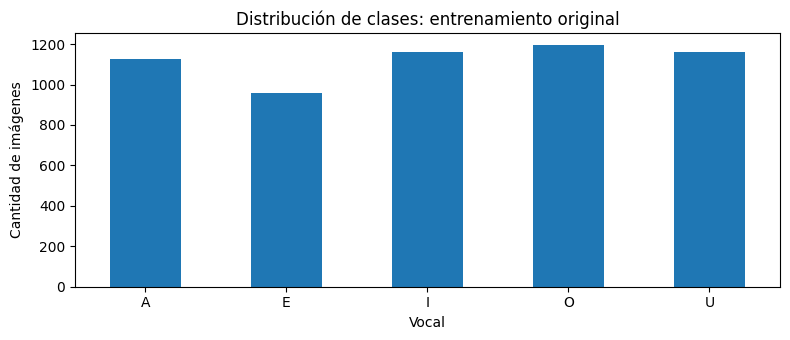

**Lectura:** Hay 5602 imágenes de las cinco vocales para entrenar/validar. La clase más frecuente tiene 1196 ejemplos y la menos frecuente 957; la distribución por clase debe considerarse al interpretar las métricas macro.

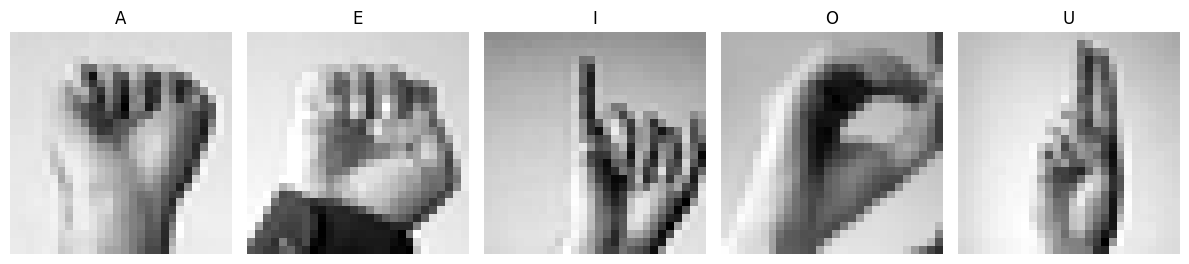

**Lectura:** Cada ejemplo corresponde a una imagen en escala de grises de 28 × 28 píxeles. Solo se utilizan las cinco vocales, como en las arquitecturas anteriores.

Train: (4481, 28, 28, 1) | Val: (1121, 28, 28, 1) | Test: (1629, 28, 28, 1)


,Conjuntos,Duplicados exactos
0,train / val,0
1,train / test,0
2,val / test,0


**Lectura:** Esta comprobación detecta imágenes idénticas, pero no imágenes casi iguales ni la presencia de una misma persona en varios conjuntos.

**Lectura:** Solo se usan A, E, I, O y U; se normaliza de 0–255 a 0–1 y se separa el 20% del train original con estratificación. El test se reserva para después de seleccionar los modelos.


2. CONSTRUCCIÓN, ENTRENAMIENTO, REGULARIZACIÓN Y OPTIMIZACIÓN


,Modelo,Experimento,Cambio,Valor,Frente a
0,MLP,Baseline,baseline,None,Baseline
1,MLP,Dropout 0.30,dropout,0.3,Baseline
2,MLP,Early Stopping,early_stopping,True,Baseline
3,MLP,LR 0.0005,learning_rate,0.0005,Baseline
4,MLP,Batch 64,batch_size,64,Baseline
5,MLP,Dropout 0.15,dropout,0.15,Baseline
6,MLP,LR 0.0002,learning_rate,0.0002,Baseline
7,MLP,L2 0.0001,l2,0.0001,Baseline
8,MLP,Neuronas 256-128,neuronas_mlp,"(256, 128)",Baseline
9,CNN,Baseline,baseline,None,Baseline


**Lectura:** Los cambios son individuales respecto al modelo indicado en 'Frente a'. Las pruebas de 20 épocas permiten comprobar Early Stopping con el mismo límite máximo.


MLP | Baseline
Cambio: baseline = None
Motivo: Obtener una referencia sin técnicas de regularización adicionales.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Baseline,0.99844,0.99822,0.9981,0.01654,0.01654,0.0,0.00022,12,12.68947,109061


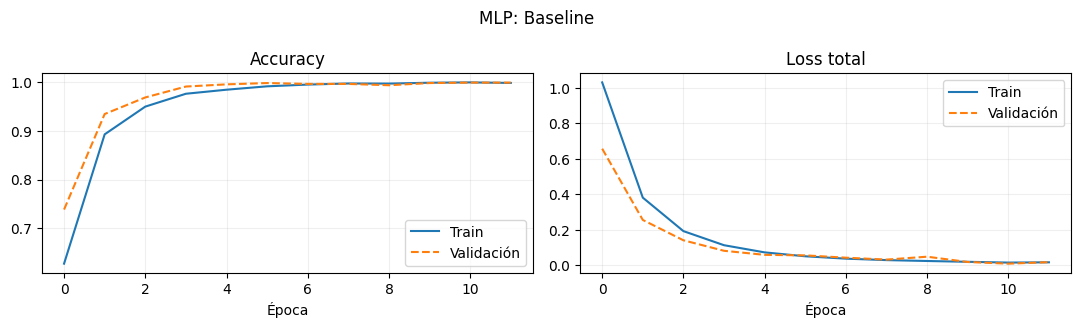

**Lectura:** Esta es la configuración de referencia; se usa para comparar los cambios individuales de la misma arquitectura.


MLP | Dropout 0.30
Cambio: dropout = 0.3
Motivo: Comprobar si desactivar neuronas mejora la generalización.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Dropout 0.30,0.98951,0.99286,0.99301,0.04414,0.04414,0.0,-0.00335,12,13.09731,109061


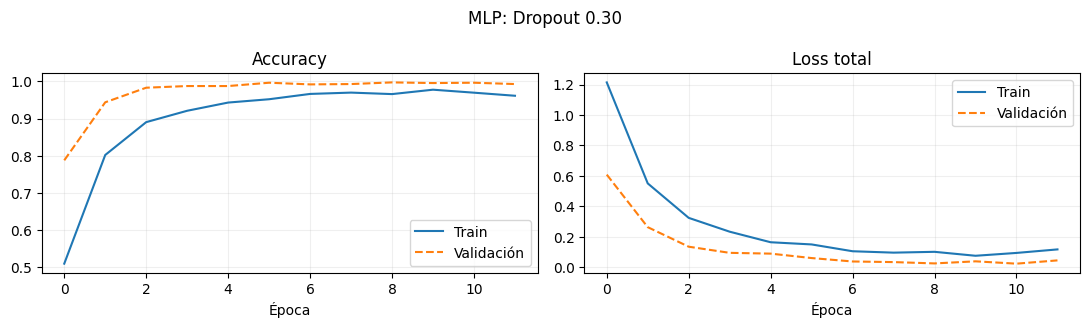

**Lectura:** Frente a **Baseline**, la F1 de validación disminuyó (Δ = -0.0051); entropía cruzada Δ = +0.02761. Usó 12/12 épocas y 109,061 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | Early Stopping
Cambio: early_stopping = True
Motivo: Comprobar si la pérdida de validación permite detener el entrenamiento antes del límite.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Early Stopping,1.0,0.99822,0.99825,0.00814,0.00814,0.0,0.00178,12,10.30017,109061


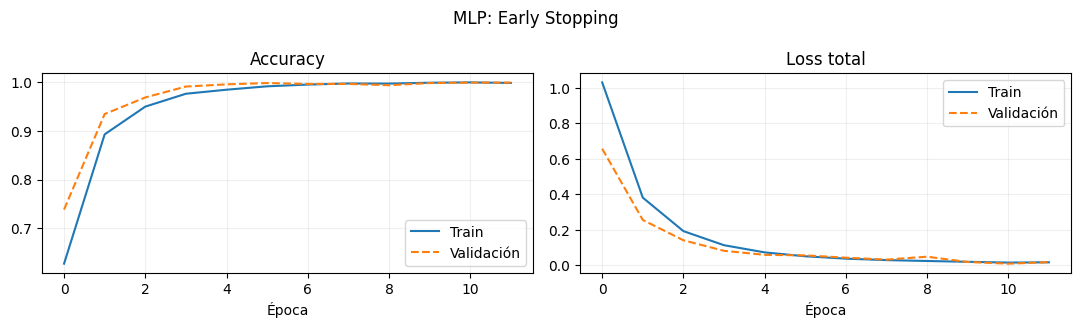

**Lectura:** Frente a **Baseline**, la F1 de validación mejoró (Δ = +0.0002); entropía cruzada Δ = -0.00839. Usó 12/12 épocas y 109,061 parámetros. Early Stopping no detuvo anticipadamente. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | LR 0.0005
Cambio: learning_rate = 0.0005
Motivo: Comparar velocidades de aprendizaje y convergencia.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,LR 0.0005,0.99955,0.99822,0.99825,0.0187,0.0187,0.0,0.00134,12,10.88435,109061


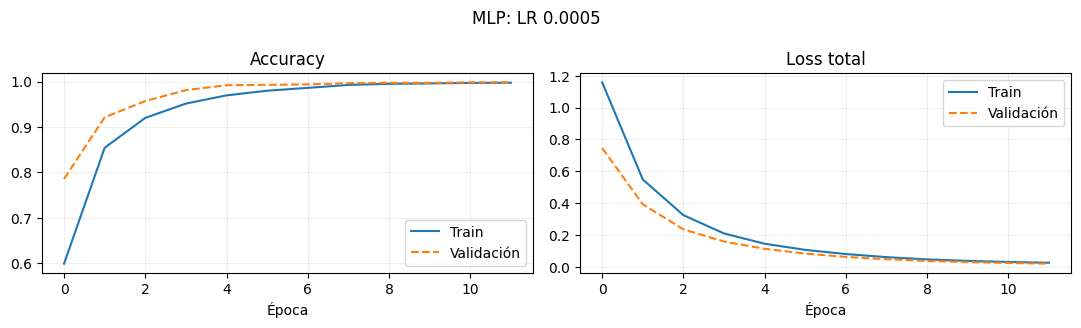

**Lectura:** Frente a **Baseline**, la F1 de validación mejoró (Δ = +0.0002); entropía cruzada Δ = +0.00216. Usó 12/12 épocas y 109,061 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | Batch 64
Cambio: batch_size = 64
Motivo: Analizar la influencia del tamaño del lote y su costo.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Batch 64,0.99464,0.98751,0.98774,0.04689,0.04689,0.0,0.00713,12,6.89299,109061


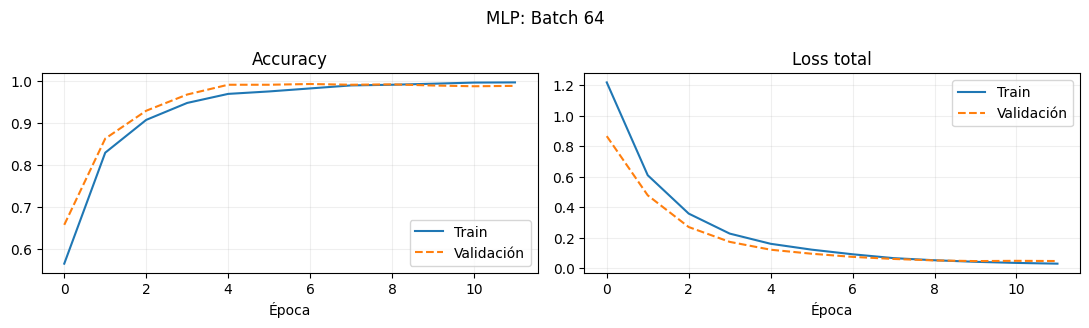

**Lectura:** Frente a **Baseline**, la F1 de validación disminuyó (Δ = -0.0104); entropía cruzada Δ = +0.03036. Usó 12/12 épocas y 109,061 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | Dropout 0.15
Cambio: dropout = 0.15
Motivo: Comprobar si desactivar neuronas mejora la generalización.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Dropout 0.15,0.99955,1.0,1.0,0.00807,0.00807,0.0,-0.00045,12,13.12729,109061


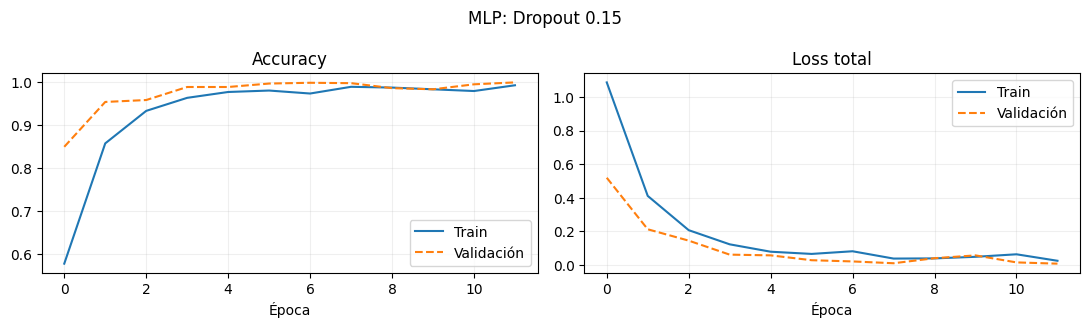

**Lectura:** Frente a **Baseline**, la F1 de validación mejoró (Δ = +0.0019); entropía cruzada Δ = -0.00846. Usó 12/12 épocas y 109,061 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | LR 0.0002
Cambio: learning_rate = 0.0002
Motivo: Comparar velocidades de aprendizaje y convergencia.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,LR 0.0002,0.99576,0.99376,0.99388,0.04917,0.04917,0.0,0.002,12,11.40874,109061


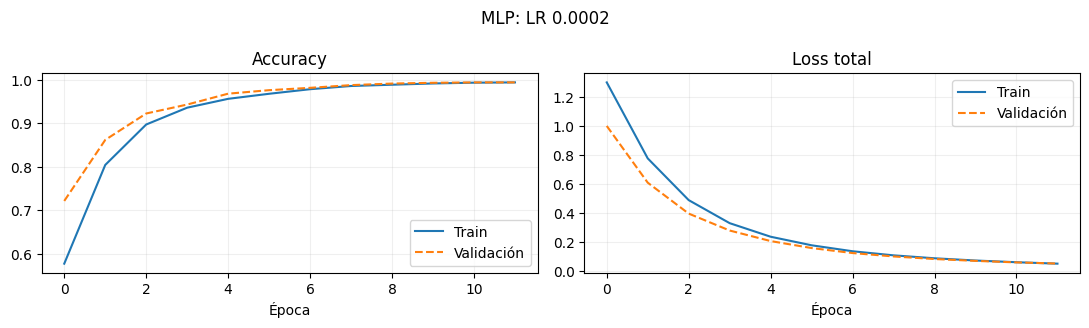

**Lectura:** Frente a **Baseline**, la F1 de validación disminuyó (Δ = -0.0042); entropía cruzada Δ = +0.03264. Usó 12/12 épocas y 109,061 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | L2 0.0001
Cambio: l2 = 0.0001
Motivo: Penalizar pesos y evaluar por separado pérdida de clasificación y penalización.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,L2 0.0001,1.0,0.99822,0.99825,0.00906,0.0265,0.01744,0.00178,12,12.52846,109061


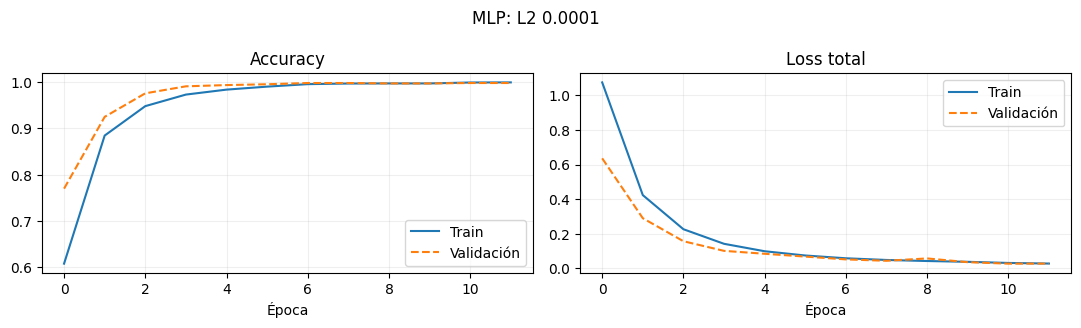

**Lectura:** Frente a **Baseline**, la F1 de validación mejoró (Δ = +0.0002); entropía cruzada Δ = -0.00748. Usó 12/12 épocas y 109,061 parámetros. Con L2, CE val=0.00906, penalización=0.01744 y pérdida total=0.02650; se comparan las CE, no pérdidas totales. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | Neuronas 256-128
Cambio: neuronas_mlp = (256, 128)
Motivo: Examinar si una MLP más amplia mejora su desempeño.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Neuronas 256-128,0.99978,0.99822,0.99825,0.00635,0.00635,0.0,0.00156,12,14.49749,234501


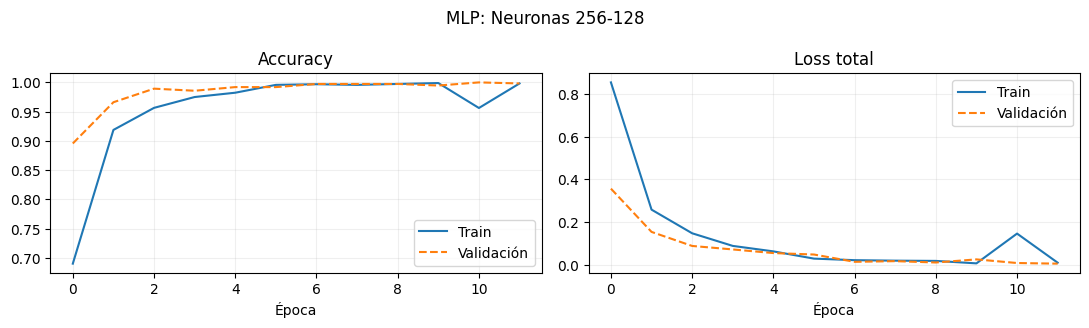

**Lectura:** Frente a **Baseline**, la F1 de validación mejoró (Δ = +0.0002); entropía cruzada Δ = -0.01019. Usó 12/12 épocas y 234,501 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Baseline
Cambio: baseline = None
Motivo: Obtener una referencia sin técnicas de regularización adicionales.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Baseline,1.0,1.0,1.0,0.00014,0.00014,0.0,0.0,12,101.84749,219909


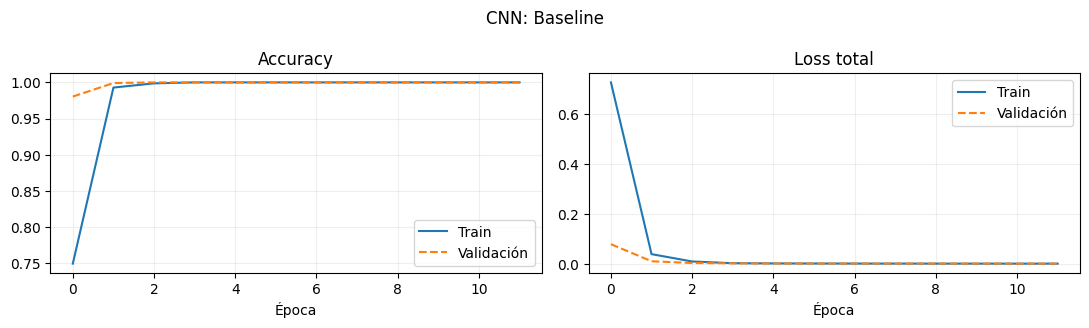

**Lectura:** Esta es la configuración de referencia; se usa para comparar los cambios individuales de la misma arquitectura.


CNN | Dropout 0.30
Cambio: dropout = 0.3
Motivo: Comprobar si desactivar neuronas mejora la generalización.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Dropout 0.30,1.0,1.0,1.0,0.00005,0.00005,0.0,0.0,12,97.78172,219909


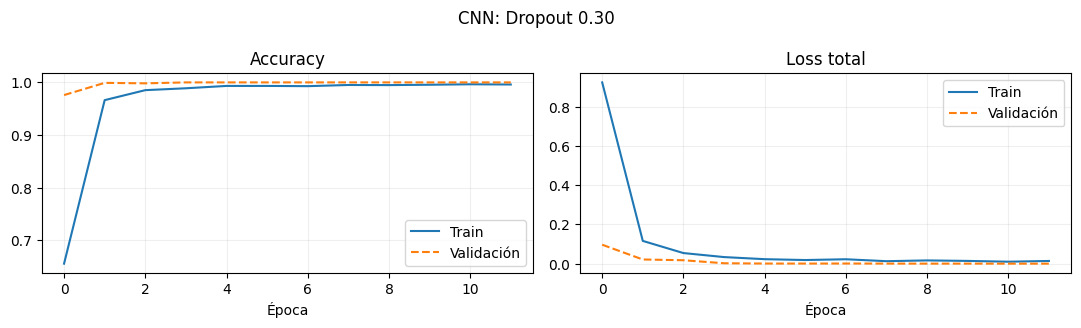

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = -0.00010. Usó 12/12 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Early Stopping
Cambio: early_stopping = True
Motivo: Comprobar si la pérdida de validación permite detener el entrenamiento antes del límite.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Early Stopping,1.0,1.0,1.0,0.00014,0.00014,0.0,0.0,12,83.93362,219909


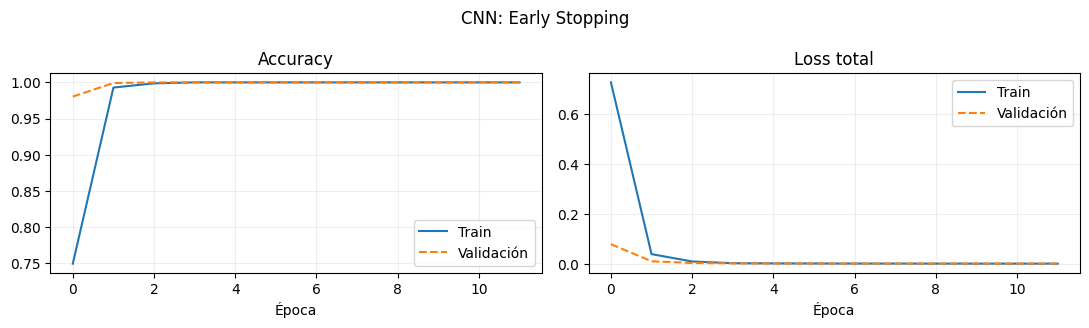

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00000. Usó 12/12 épocas y 219,909 parámetros. Early Stopping no detuvo anticipadamente. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | LR 0.0005
Cambio: learning_rate = 0.0005
Motivo: Comparar velocidades de aprendizaje y convergencia.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,LR 0.0005,1.0,1.0,1.0,0.0005,0.0005,0.0,0.0,12,88.53573,219909


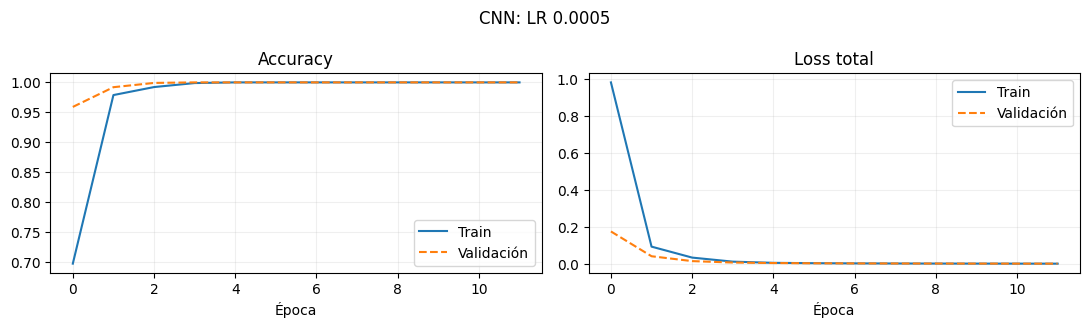

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00036. Usó 12/12 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Batch 64
Cambio: batch_size = 64
Motivo: Analizar la influencia del tamaño del lote y su costo.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Batch 64,1.0,1.0,1.0,0.00048,0.00048,0.0,0.0,12,75.54892,219909


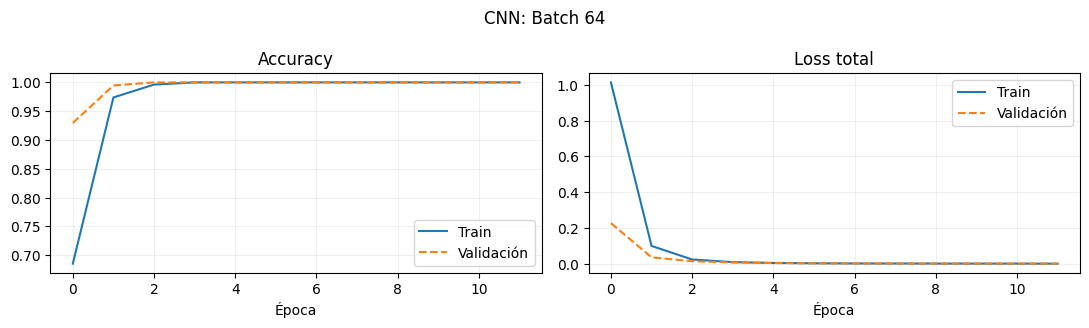

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00033. Usó 12/12 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Data Augmentation
Cambio: aumento = True
Motivo: Introducir pequeñas variaciones durante entrenamiento, sin alterar validación.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Data Augmentation,1.0,1.0,1.0,0.00064,0.00064,0.0,0.0,12,82.55615,219909


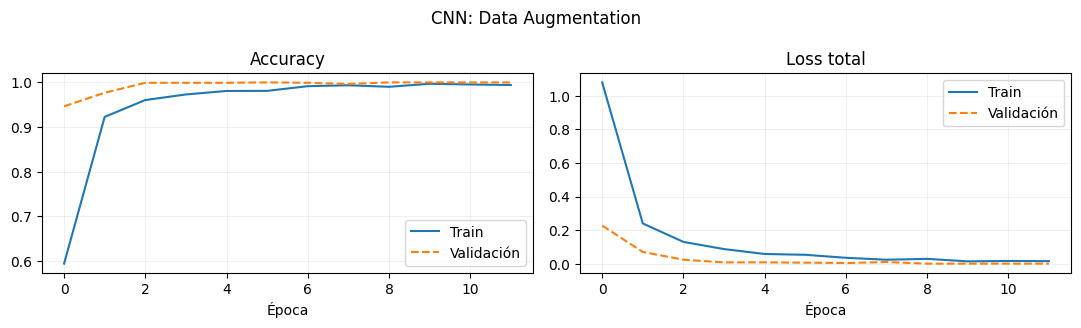

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00049. Usó 12/12 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | L2 0.0001
Cambio: l2 = 0.0001
Motivo: Penalizar pesos y evaluar por separado pérdida de clasificación y penalización.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,L2 0.0001,1.0,1.0,1.0,0.00107,0.01173,0.01066,0.0,12,98.43676,219909


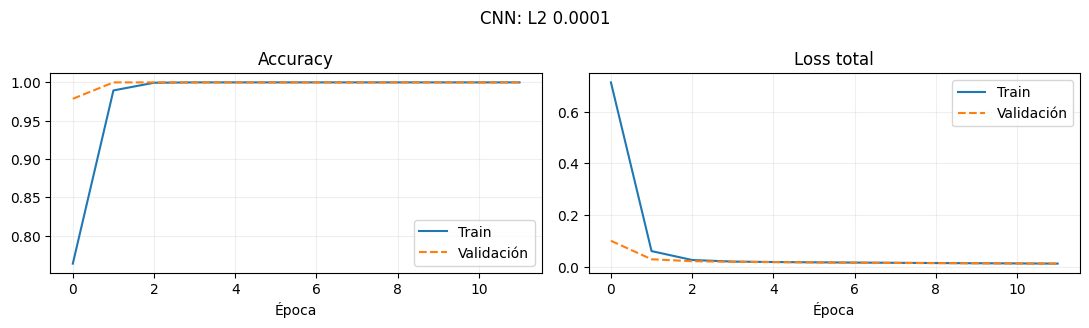

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00093. Usó 12/12 épocas y 219,909 parámetros. Con L2, CE val=0.00107, penalización=0.01066 y pérdida total=0.01173; se comparan las CE, no pérdidas totales. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Batch Normalization
Cambio: batch_norm = True
Motivo: Evaluar si la normalización de activaciones modifica el aprendizaje.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Batch Normalization,1.0,1.0,1.0,0.00004,0.00004,0.0,0.0,12,109.33977,220293


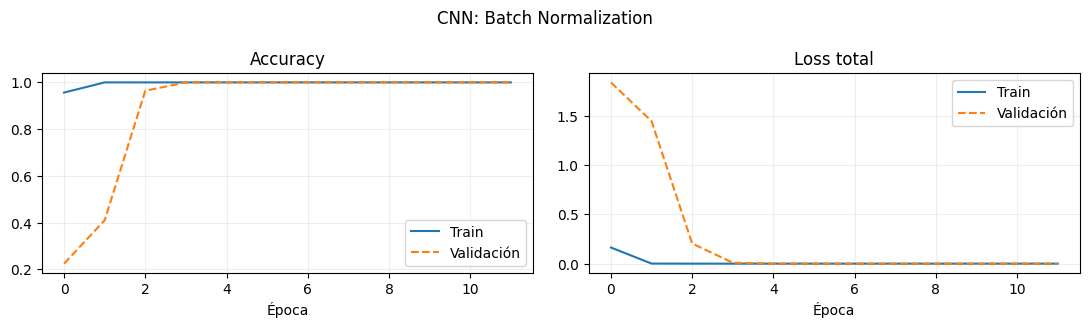

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = -0.00010. Usó 12/12 épocas y 220,293 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Dropout 0.15
Cambio: dropout = 0.15
Motivo: Comprobar si desactivar neuronas mejora la generalización.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Dropout 0.15,1.0,1.0,1.0,0.00011,0.00011,0.0,0.0,12,85.00112,219909


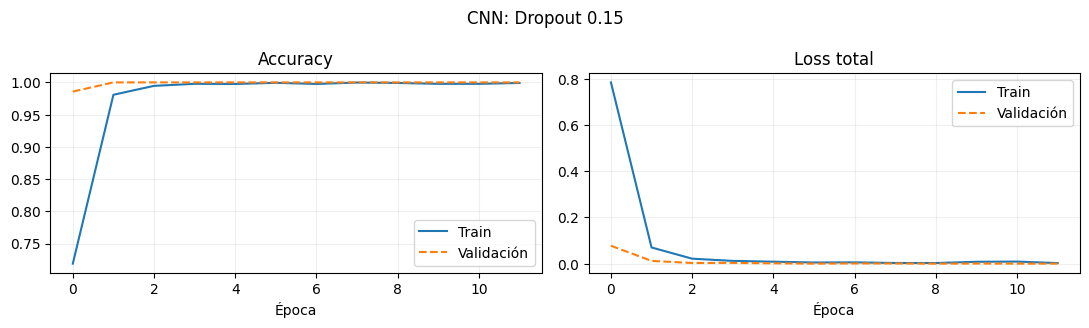

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = -0.00004. Usó 12/12 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | LR 0.0002
Cambio: learning_rate = 0.0002
Motivo: Comparar velocidades de aprendizaje y convergencia.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,LR 0.0002,1.0,1.0,1.0,0.00323,0.00323,0.0,0.0,12,88.73145,219909


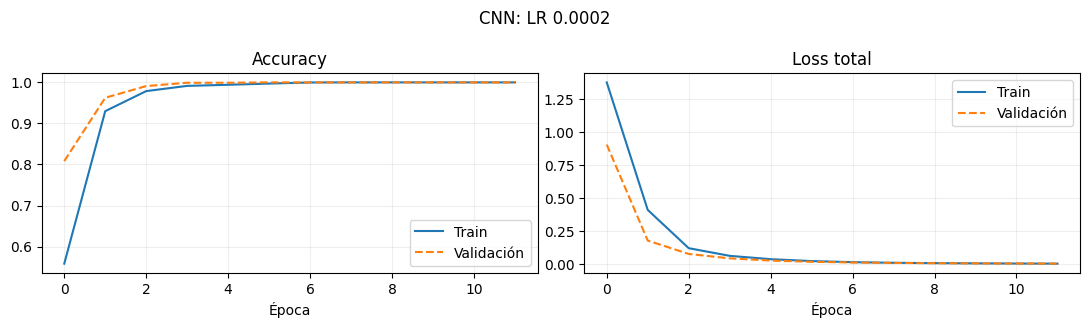

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00308. Usó 12/12 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Filtros 24-48
Cambio: filtros = (24, 48)
Motivo: Reducir la complejidad de la CNN conservando los patrones espaciales.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Filtros 24-48,1.0,1.0,1.0,0.00023,0.00023,0.0,0.0,12,64.44378,161573


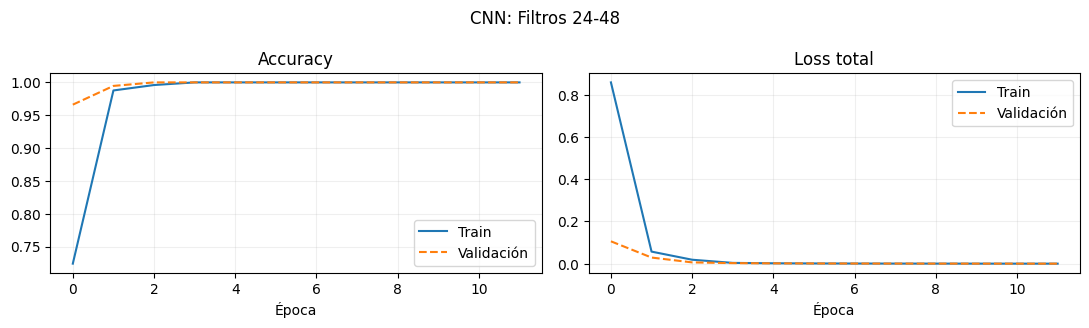

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00009. Usó 12/12 épocas y 161,573 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Densa 128
Cambio: neuronas_cnn = 128
Motivo: Examinar el efecto del tamaño de la capa densa de la CNN.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Densa 128,1.0,1.0,1.0,0.00004,0.00004,0.0,0.0,12,84.74233,420997


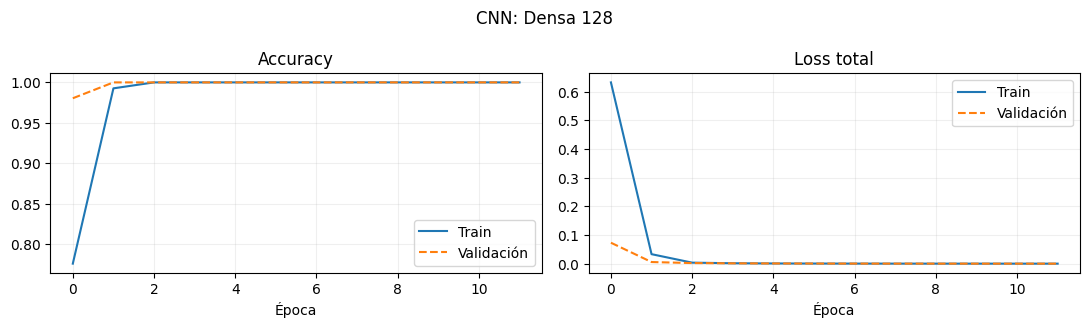

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = -0.00010. Usó 12/12 épocas y 420,997 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Filtros 16-32
Cambio: filtros = (16, 32)
Motivo: Reducir la complejidad de la CNN conservando los patrones espaciales.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Filtros 16-32,1.0,1.0,1.0,0.00037,0.00037,0.0,0.0,12,48.6611,105541


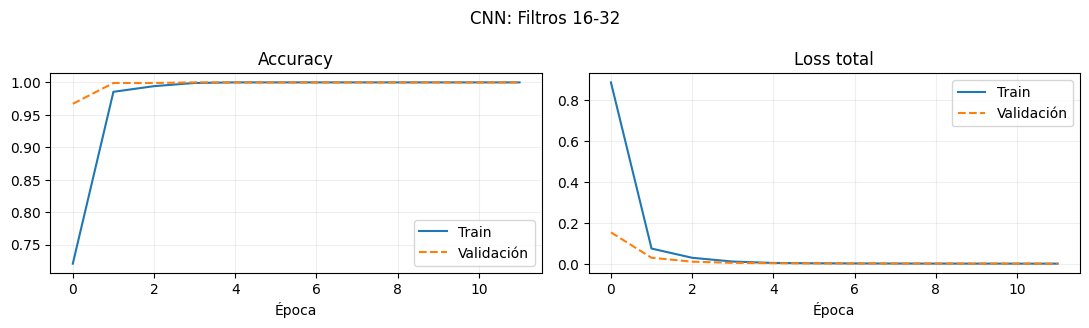

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00023. Usó 12/12 épocas y 105,541 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Filtros 12-24
Cambio: filtros = (12, 24)
Motivo: Reducir la complejidad de la CNN conservando los patrones espaciales.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Filtros 12-24,1.0,1.0,1.0,0.00033,0.00033,0.0,0.0,12,49.06693,78389


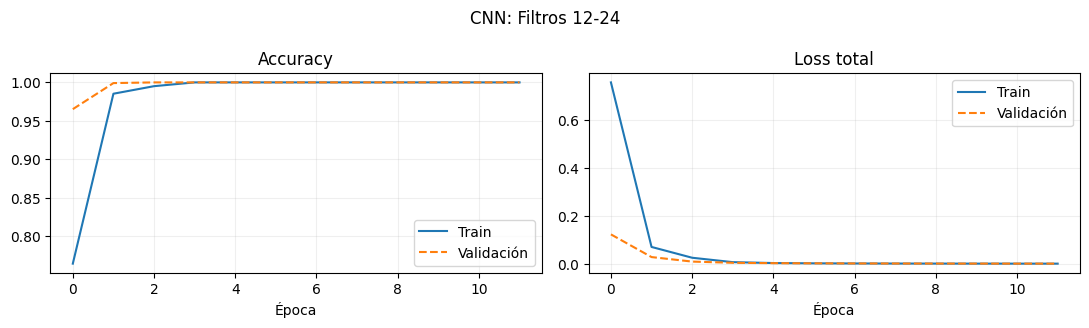

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00019. Usó 12/12 épocas y 78,389 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Densa 32
Cambio: neuronas_cnn = 32
Motivo: Examinar el efecto del tamaño de la capa densa de la CNN.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Densa 32,1.0,1.0,1.0,0.00023,0.00023,0.0,0.0,12,78.78711,119365


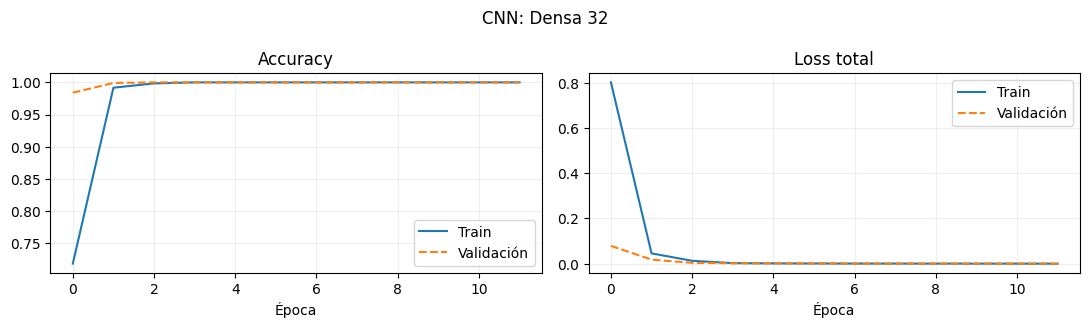

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00008. Usó 12/12 épocas y 119,365 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | 20 epocas
Cambio: epocas = 20
Motivo: Comprobar si más épocas ofrecen alguna mejora antes de aplicar Early Stopping.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,20 epocas,1.0,1.0,1.0,0.00004,0.00004,0.0,0.0,20,163.36625,219909


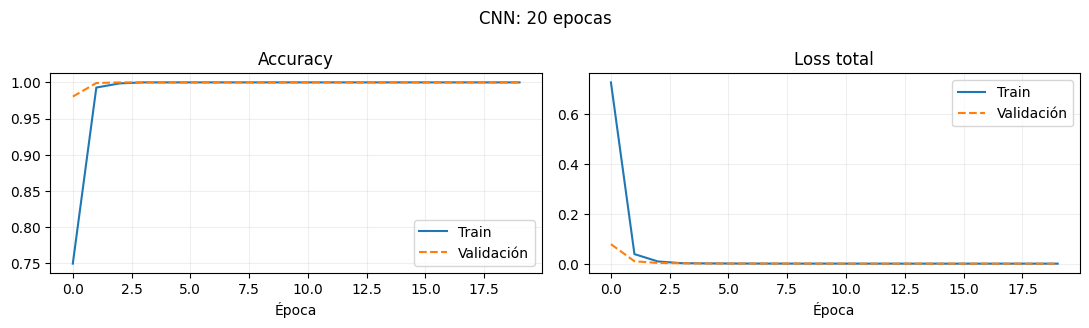

**Lectura:** Frente a **Baseline**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = -0.00010. Usó 20/20 épocas y 219,909 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | 20 epocas + ES
Cambio: early_stopping = True
Motivo: Comprobar si la pérdida de validación permite detener el entrenamiento antes del límite.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,20 epocas + ES,1.0,1.0,1.0,0.00004,0.00004,0.0,0.0,20,145.95185,219909


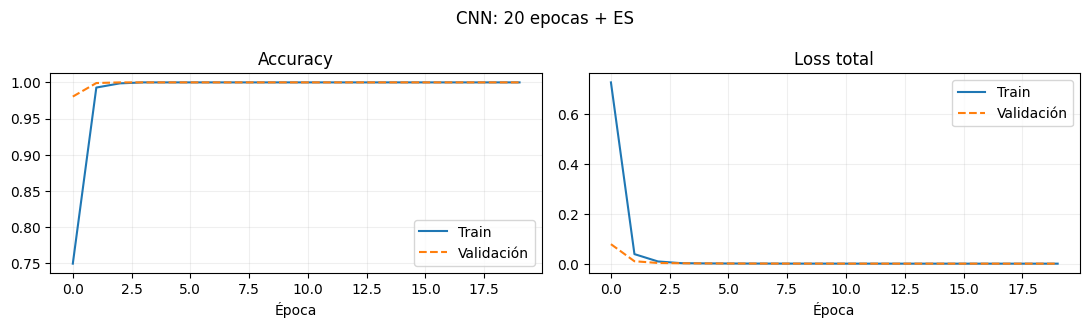

**Lectura:** Frente a **20 epocas**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00000. Usó 20/20 épocas y 219,909 parámetros. Early Stopping no detuvo anticipadamente. Una sola ejecución no demuestra por sí sola mejor generalización.


MLP | Combinacion controlada
Cambio: neuronas_mlp = (256, 128)
Motivo: Evaluar si añadir neuronas_mlp a Dropout 0.15 produce una mejora medible; un segundo cambio no garantiza mejora.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Combinacion controlada,0.96987,0.96253,0.9632,0.09366,0.09366,0.0,0.00734,12,15.64747,234501


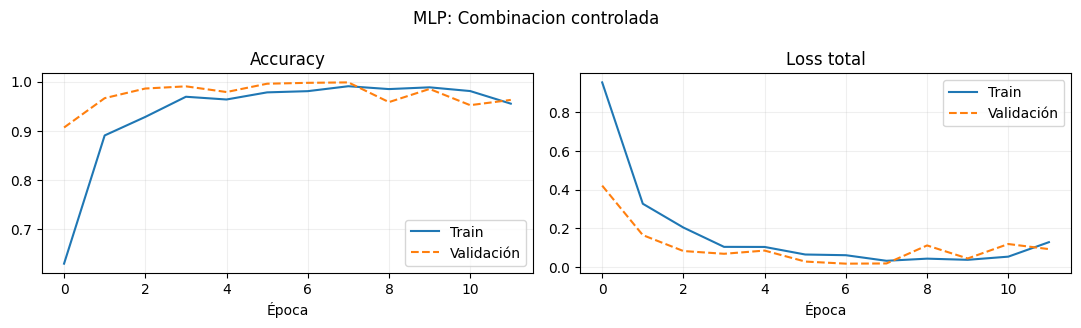

**Lectura:** Frente a **Dropout 0.15**, la F1 de validación disminuyó (Δ = -0.0368); entropía cruzada Δ = +0.08558. Usó 12/12 épocas y 234,501 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.


CNN | Combinacion controlada
Cambio: neuronas_cnn = 128
Motivo: Evaluar si añadir neuronas_cnn a Batch Normalization produce una mejora medible; un segundo cambio no garantiza mejora.


,Modelo,Experimento,Acc train,Acc val,F1 val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,CNN,Combinacion controlada,1.0,1.0,1.0,0.00004,0.00004,0.0,0.0,12,109.51142,421381


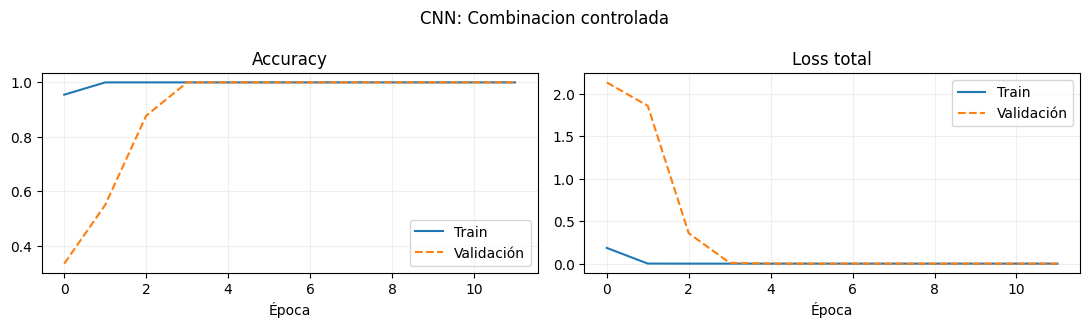

**Lectura:** Frente a **Batch Normalization**, la F1 de validación fue prácticamente igual (Δ = +0.0000); entropía cruzada Δ = +0.00000. Usó 12/12 épocas y 421,381 parámetros. Una sola ejecución no demuestra por sí sola mejor generalización.

,Modelo,Experimento,Padre,Cambio,F1 val,Acc val,CE val,Loss total val,Penalización L2,Brecha acc,Epocas,Tiempo (s),Parametros
0,MLP,Baseline,Baseline,baseline,0.99810,0.99822,0.01654,0.01654,0.00000,0.00022,12,12.68947,109061
1,MLP,Dropout 0.30,Baseline,dropout,0.99301,0.99286,0.04414,0.04414,0.00000,-0.00335,12,13.09731,109061
2,MLP,Early Stopping,Baseline,early_stopping,0.99825,0.99822,0.00814,0.00814,0.00000,0.00178,12,10.30017,109061
3,MLP,LR 0.0005,Baseline,learning_rate,0.99825,0.99822,0.01870,0.01870,0.00000,0.00134,12,10.88435,109061
4,MLP,Batch 64,Baseline,batch_size,0.98774,0.98751,0.04689,0.04689,0.00000,0.00713,12,6.89299,109061
5,MLP,Dropout 0.15,Baseline,dropout,1.00000,1.00000,0.00807,0.00807,0.00000,-0.00045,12,13.12729,109061
6,MLP,LR 0.0002,Baseline,learning_rate,0.99388,0.99376,0.04917,0.04917,0.00000,0.00200,12,11.40874,109061
7,MLP,L2 0.0001,Baseline,l2,0.99825,0.99822,0.00906,0.02650,0.01744,0.00178,12,12.52846,109061
8,MLP,Neuronas 256-128,Baseline,neuronas_mlp,0.99825,0.99822,0.00635,0.00635,0.00000,0.00156,12,14.49749,234501
9,CNN,Baseline,Baseline,baseline,1.00000,1.00000,0.00014,0.00014,0.00000,0.00000,12,101.84749,219909


**Lectura:** CE val se compara sin sumar L2; Loss total val incluye su penalización. Cuando varias F1 son 1,00 no debe asumirse que el modelo de mayor tamaño es superior.

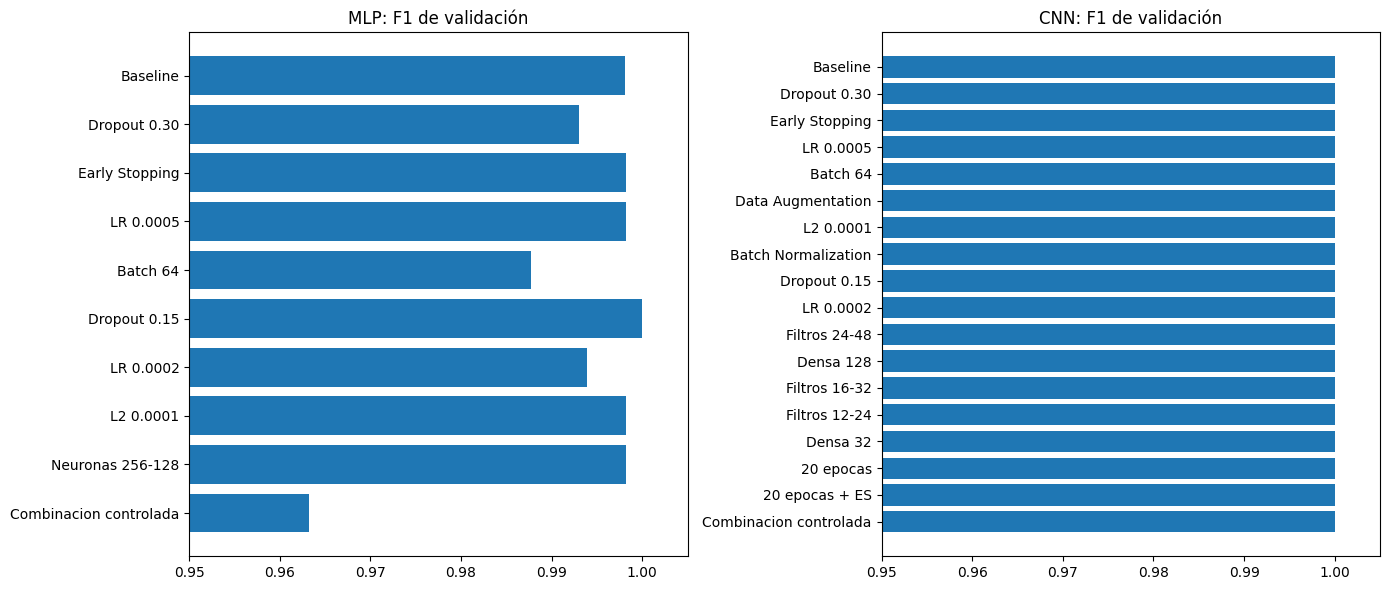

**Lectura:** Las barras comparan el desempeño macro con la misma partición. El eje se recorta para mostrar diferencias pequeñas.

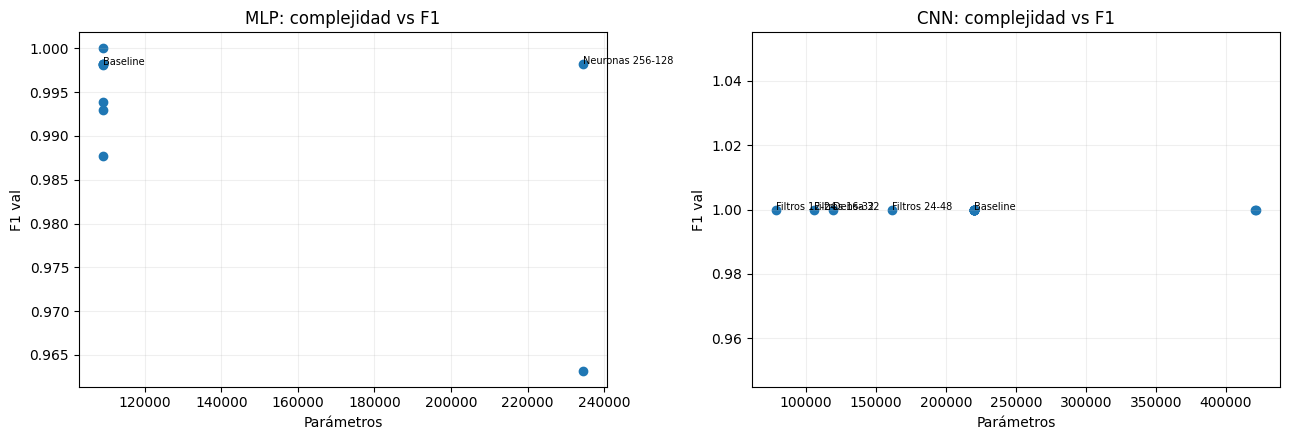

**Lectura:** Se busca un desempeño alto sin incrementar innecesariamente el número de parámetros. El tiempo de entrenamiento depende del equipo usado.

,Modelo,Experimento,Respecto a,Δ F1,Δ CE,Δ parámetros,Δ tiempo (s)
0,MLP,Dropout 0.30,Baseline,-0.00509,0.02761,0,0.40783
1,MLP,Early Stopping,Baseline,0.00015,-0.00839,0,-2.38931
2,MLP,LR 0.0005,Baseline,0.00015,0.00216,0,-1.80512
3,MLP,Batch 64,Baseline,-0.01036,0.03036,0,-5.79649
4,MLP,Dropout 0.15,Baseline,0.00190,-0.00846,0,0.43782
5,MLP,LR 0.0002,Baseline,-0.00422,0.03264,0,-1.28073
6,MLP,L2 0.0001,Baseline,0.00015,-0.00748,0,-0.16101
7,MLP,Neuronas 256-128,Baseline,0.00015,-0.01019,125440,1.80801
8,CNN,Dropout 0.30,Baseline,0.00000,-0.00010,0,-4.06577
9,CNN,Early Stopping,Baseline,0.00000,0.00000,0,-17.91387


**Lectura:** Cada diferencia se calcula contra su experimento padre. Un resultado negativo o sin mejora también sirve para descartar configuraciones.


3. SEGUNDA VALIDACIÓN, ROBUSTEZ Y SELECCIÓN


**Lectura:** Las configuraciones finalistas se fijan antes de evaluar test. Se incluyen deliberadamente las CNN pequeñas para comprobar si mantienen el desempeño.

Validación adicional: MLP | Baseline
Robustez en validación:


... (23 outputs left out)

Validación adicional: CNN | 20 epocas + ES
Robustez en validación:


,Condición,Accuracy split29,F1 macro split29,Accuracy split41,F1 macro split41
0,Original,1.0000,1.0000,1.0000,1.0000
1,Oscurecer 12%,1.0000,1.0000,1.0000,1.0000
2,Desplazar 1px,0.9955,0.9955,0.9857,0.9858
3,Ruido suave,1.0000,1.0000,1.0000,1.0000


**CNN, 20 epocas + ES:** F1 normal media=1.0000; F1 media bajo perturbaciones=0.9969. Estas pruebas sintéticas no sustituyen fotografías externas.

,Modelo,Experimento,F1 split29,F1 split41,F1 media,Robustez split29,Robustez split41,Robustez media,CE media,Parametros,Tiempo (s),Epocas
3,CNN,Baseline,1.00000,1.00000,1.00000,0.99788,0.99591,0.99689,0.00012,219909,101.84749,12
4,CNN,Filtros 24-48,1.00000,1.00000,1.00000,0.99583,0.99301,0.99442,0.00030,161573,64.44378,12
5,CNN,Filtros 16-32,1.00000,1.00000,1.00000,0.99446,0.99332,0.99389,0.00039,105541,48.66110,12
6,CNN,Filtros 12-24,1.00000,1.00000,1.00000,0.99357,0.99444,0.99401,0.00035,78389,49.06693,12
7,CNN,20 epocas,1.00000,1.00000,1.00000,0.99849,0.99528,0.99688,0.00003,219909,163.36625,20
8,CNN,20 epocas + ES,1.00000,1.00000,1.00000,0.99849,0.99528,0.99688,0.00003,219909,145.95185,20
0,MLP,Baseline,0.99810,1.00000,0.99905,0.96168,0.97415,0.96792,0.01265,109061,12.68947,12
1,MLP,Neuronas 256-128,0.99825,0.99913,0.99869,0.96715,0.98014,0.97365,0.00550,234501,14.49749,12
2,MLP,Dropout 0.15,1.00000,0.99476,0.99738,0.97147,0.96174,0.96661,0.01462,109061,13.12729,12


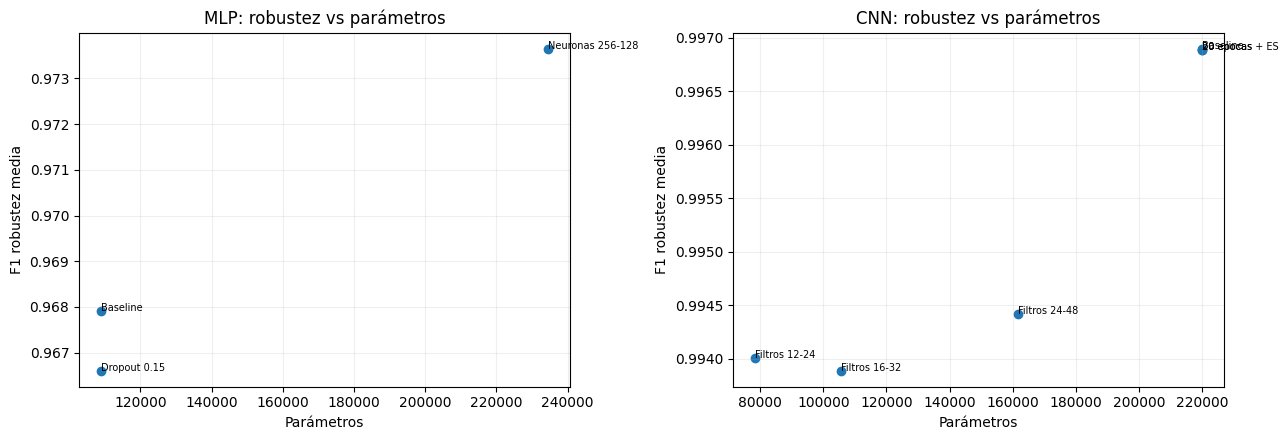

**Lectura:** La robustez se calcula solo con imágenes de validación transformadas. No representa el comportamiento ante todas las condiciones reales.

Elegido MLP: Baseline | F1 media=0.9991, robustez media=0.9679, parámetros=109,061
Elegido CNN: Filtros 12-24 | F1 media=1.0000, robustez media=0.9940, parámetros=78,389


**Modelo recomendado por validación:** CNN. Regla previa: F1 media a 0.002 del máximo, robustez media a 0.015 del máximo y luego menor número de parámetros. Los umbrales son criterios prácticos de este experimento, no garantías estadísticas.


3B. DESPLAZAMIENTOS Y DATA AUGMENTATION


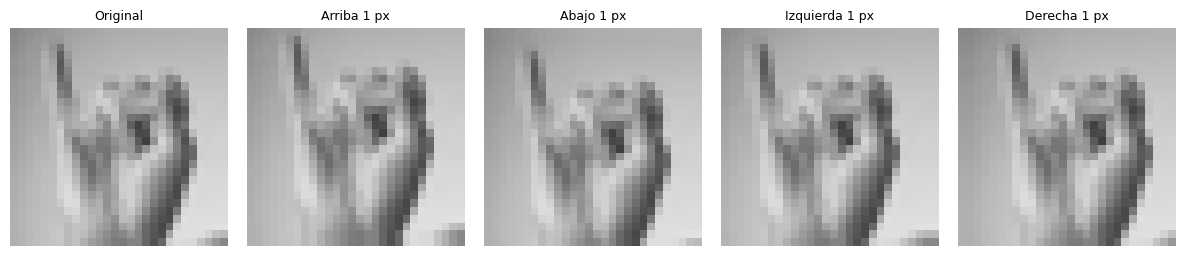

Partición 29 | Sin aumento: 52.8 s
Partición 29 | Con aumento: 49.5 s


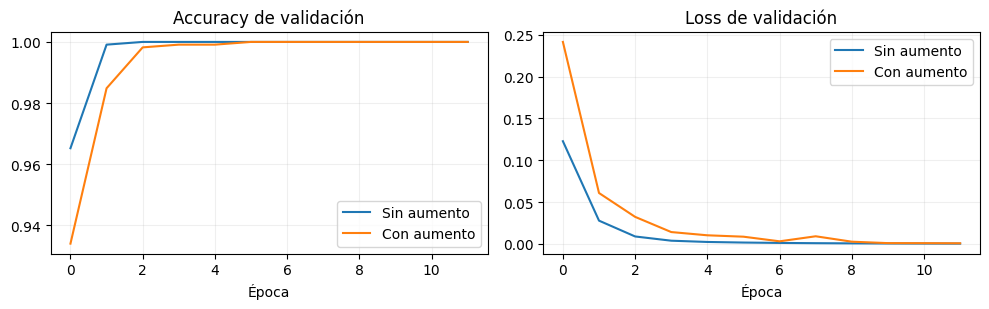

Partición 41 | Sin aumento: 47.3 s
Partición 41 | Con aumento: 46.9 s


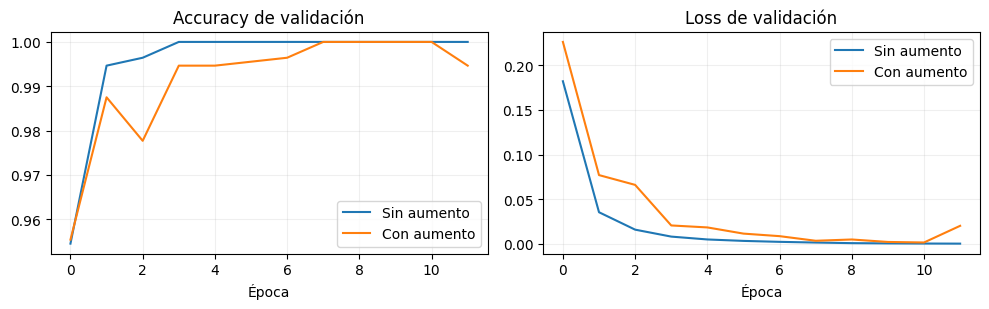

,Partición,Modelo,Condición,Accuracy,F1 macro
0,29,Sin aumento,Original,1.0000,1.0000
1,29,Sin aumento,Arriba 1 px,0.9875,0.9879
2,29,Sin aumento,Abajo 1 px,0.9759,0.9766
3,29,Sin aumento,Izquierda 1 px,0.9786,0.9793
4,29,Sin aumento,Derecha 1 px,0.9822,0.9823
5,29,Sin aumento,Oscurecer 12%,1.0000,1.0000
6,29,Sin aumento,Ruido suave,1.0000,1.0000
7,29,Con aumento,Original,1.0000,1.0000
8,29,Con aumento,Arriba 1 px,1.0000,1.0000
9,29,Con aumento,Abajo 1 px,1.0000,1.0000


Modelo,Con aumento,Sin aumento,Diferencia con aumento
Condición,,,
Original,0.9974,1.0000,-0.0026
Arriba 1 px,0.9943,0.9901,0.0042
Abajo 1 px,0.9845,0.9817,0.0028
Izquierda 1 px,0.9891,0.9784,0.0107
Derecha 1 px,0.9983,0.9821,0.0162
Oscurecer 12%,0.9939,1.0000,-0.0061
Ruido suave,0.9861,1.0000,-0.0139


,Modelo,F1 original media,F1 desplazamientos media,Peor F1 desplazamientos,Tiempo medio (s),Parámetros
0,Sin aumento,1.0000,0.9831,0.9766,50.0794,78389
1,Con aumento,0.9974,0.9916,0.9689,48.2407,78389


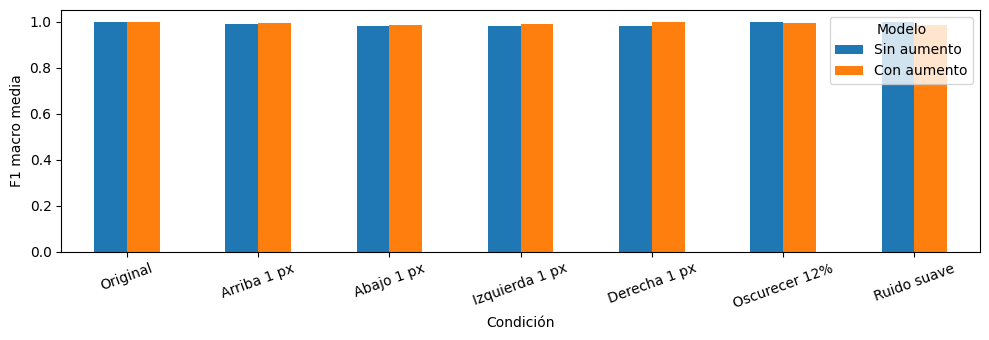

**Lectura:** La diferencia media de F1 ante desplazamientos fue +0.0085 al incorporar Data Augmentation. Revisar también el peor caso y el tiempo de entrenamiento.


4. EVALUACIÓN DE MODELOS SELECCIONADOS EN PRUEBA


,Modelo,Configuración,Accuracy,Precision macro,Recall macro,F1 macro,ROC-AUC macro,Tiempo (s),Parámetros
0,MLP,Baseline,0.94414,0.94506,0.93052,0.93605,0.99743,12.68947,109061
1,CNN,Filtros 12-24,0.99939,0.99940,0.99919,0.99929,1.00000,49.06693,78389


**Lectura:** Test describe los modelos elegidos por validación; no se utilizará para modificar su configuración. Este CSV ya se había examinado en V1/V2, así que no constituye una evaluación completamente independiente del proyecto.

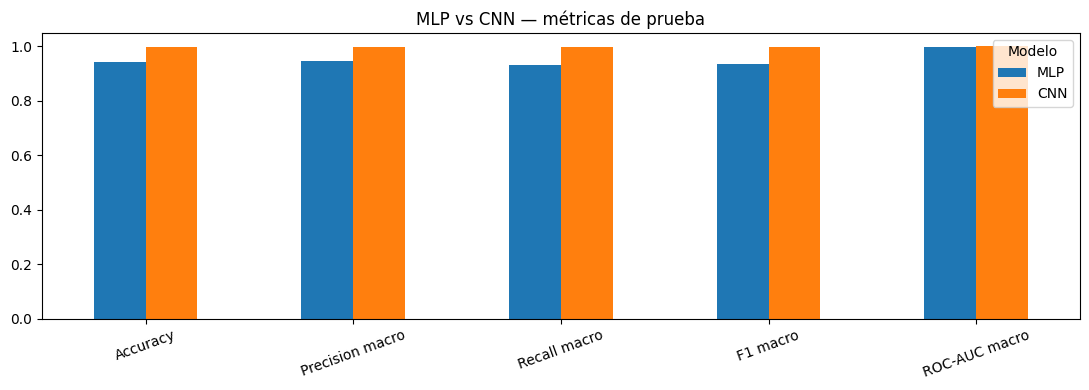

**Lectura:** Accuracy indica aciertos generales; F1 macro pondera por igual el rendimiento por vocal y ROC-AUC OvR resume discriminación multiclase.

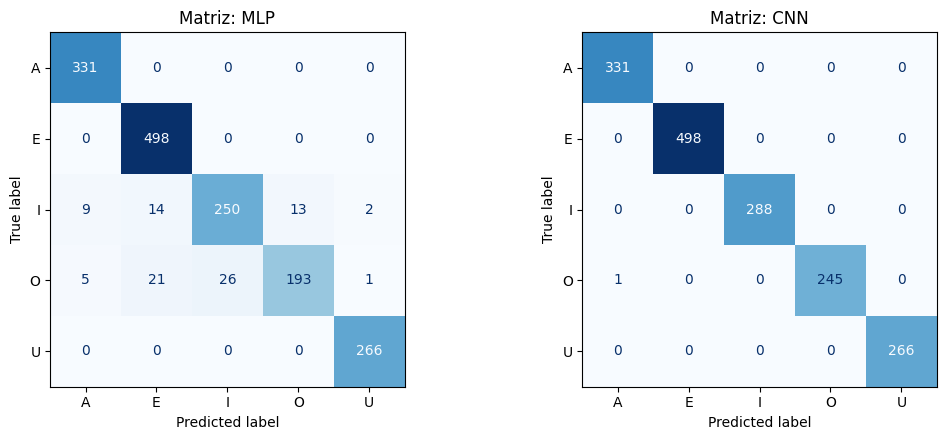

**MLP:** 91 errores; principal confusión: O → I (26). Las filas indican la vocal real; las columnas, la predicha.

,precision,recall,f1-score,support
A,0.9594,1.0000,0.9793,331.0
E,0.9343,1.0000,0.9661,498.0
I,0.9058,0.8681,0.8865,288.0
O,0.9369,0.7846,0.8540,246.0
U,0.9888,1.0000,0.9944,266.0


**CNN:** 1 errores; principal confusión: O → A (1). Las filas indican la vocal real; las columnas, la predicha.

,precision,recall,f1-score,support
A,0.997,1.0000,0.9985,331.0
E,1.000,1.0000,1.0000,498.0
I,1.000,1.0000,1.0000,288.0
O,1.000,0.9959,0.9980,246.0
U,1.000,1.0000,1.0000,266.0


MLP: 91 errores de 1629 imágenes (5.59 %)
CNN: 1 errores de 1629 imágenes (0.06 %)


,Imagen test,Real,Predicción MLP,Predicción CNN
0,486,O,A,A
1,21,O,E,O
2,28,O,E,O
3,30,O,I,O
4,38,O,E,O
5,0,A,A,A
6,1,O,O,O
7,2,I,I,I


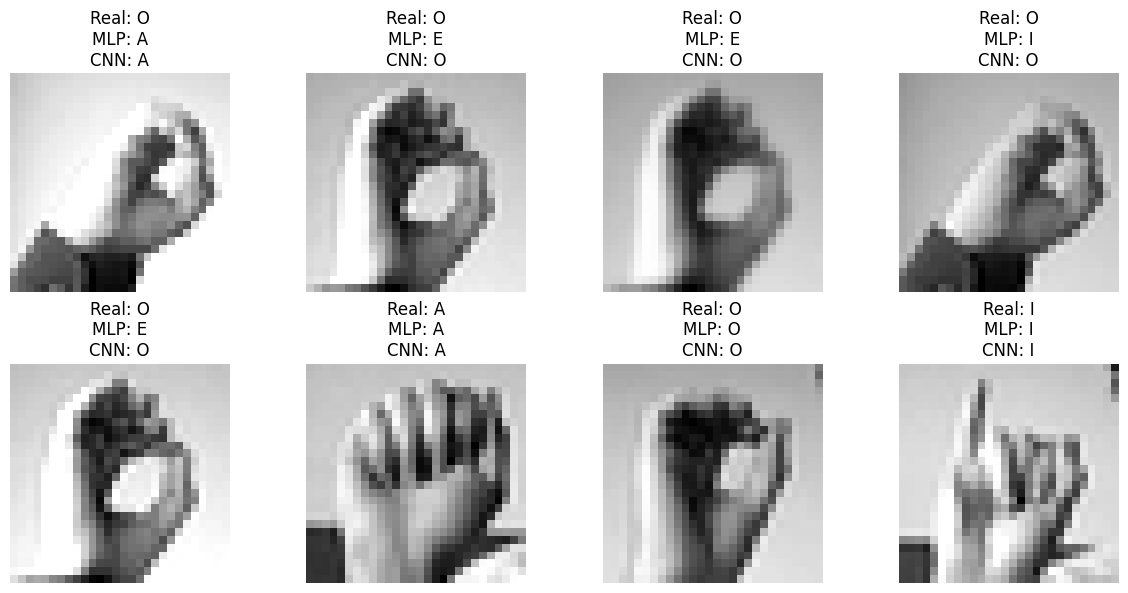


5. AUDITORÍA DE ERRORES, CLASES Y EXPLICABILIDAD


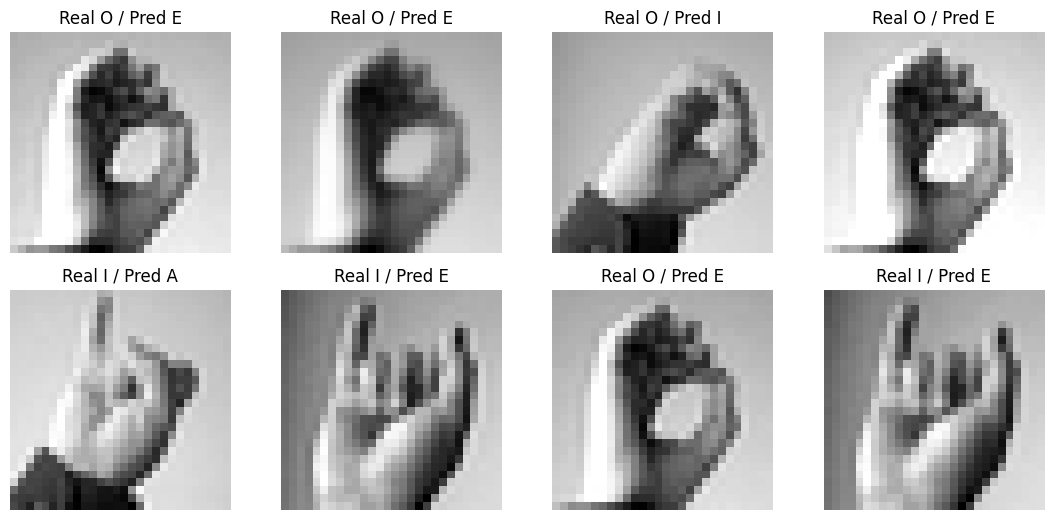

**Lectura:** Ejemplos reales de errores de MLP; son material de auditoría, no ejemplos para volver a ajustar hiperparámetros.

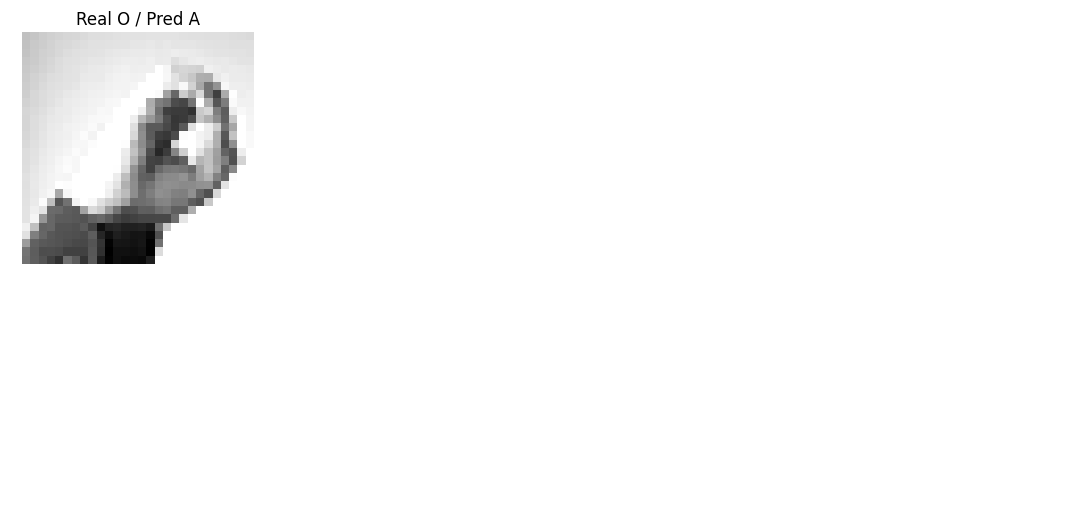

**Lectura:** Ejemplos reales de errores de CNN; son material de auditoría, no ejemplos para volver a ajustar hiperparámetros.

,Vocal,Train,Validación,Test,Recall MLP,F1 MLP,Recall CNN,F1 CNN
0,A,901,225,331,1.0000,0.9793,1.0000,0.9985
1,E,765,192,498,1.0000,0.9661,1.0000,1.0000
2,I,929,233,288,0.8681,0.8865,1.0000,1.0000
3,O,957,239,246,0.7846,0.8540,0.9959,0.9980
4,U,929,232,266,1.0000,0.9944,1.0000,1.0000


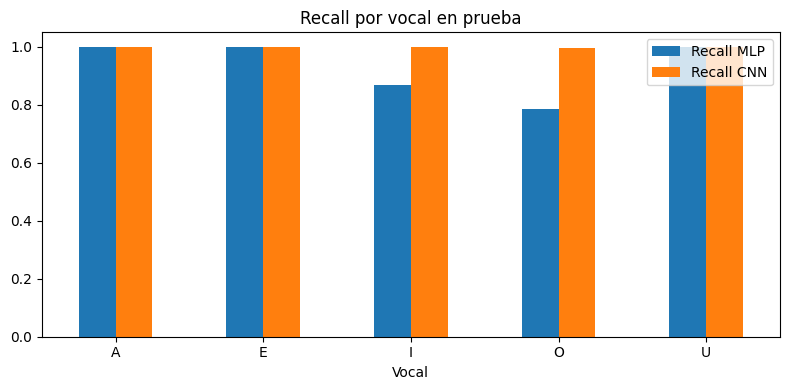

**MLP:** Recall mínimo en O (0.7846); brecha entre vocales=0.2154.

**CNN:** Recall mínimo en O (0.9959); brecha entre vocales=0.0041.

Conjunto,test,train,val
Vocal,,,
A,0.6592,0.6293,0.6319
E,0.6338,0.6441,0.6472
I,0.6495,0.6593,0.6607
O,0.6148,0.6149,0.6167
U,0.6744,0.6343,0.6268


**Lectura:** Se comparan diferencias observables de intensidad media; no se infiere que el brillo cause los errores. El CSV no contiene datos de edad, identidad u otras variables necesarias para evaluar equidad demográfica.

**Mitigación propuesta:** Evaluar imágenes externas con distintas manos, cámaras, iluminación y fondos, respetando consentimiento y privacidad. Una clasificación perfecta en este CSV no asegura rendimiento universal.

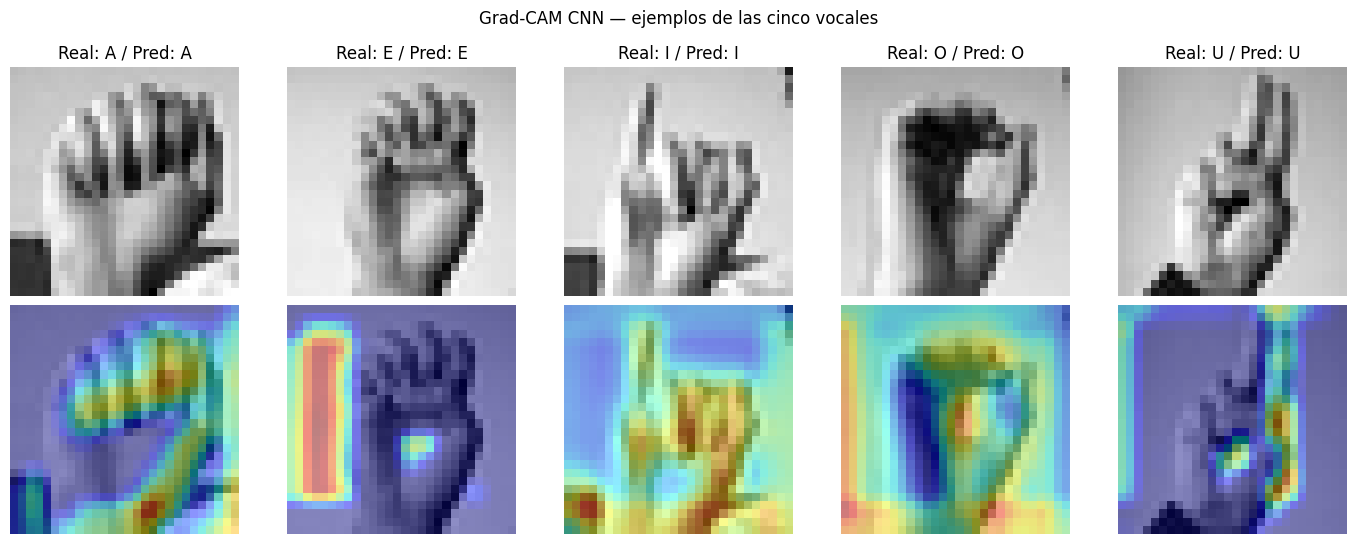

**Lectura:** El mapa resalta regiones que contribuyen a la puntuación de la clase predicha. Es una explicación aproximada: la zona destacada no demuestra por sí sola que el modelo esté razonando correctamente.

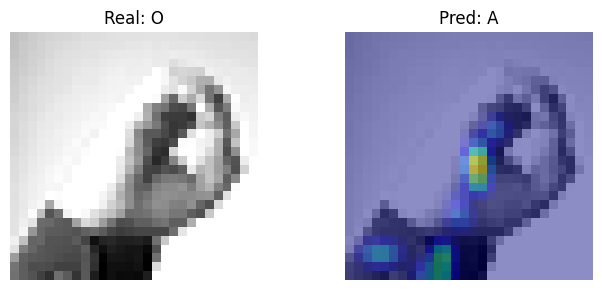

**Lectura:** Se muestra un error real de la CNN con su explicación Grad-CAM para revisar visualmente las regiones destacadas. No se modificarán hiperparámetros a partir de este ejemplo de test.

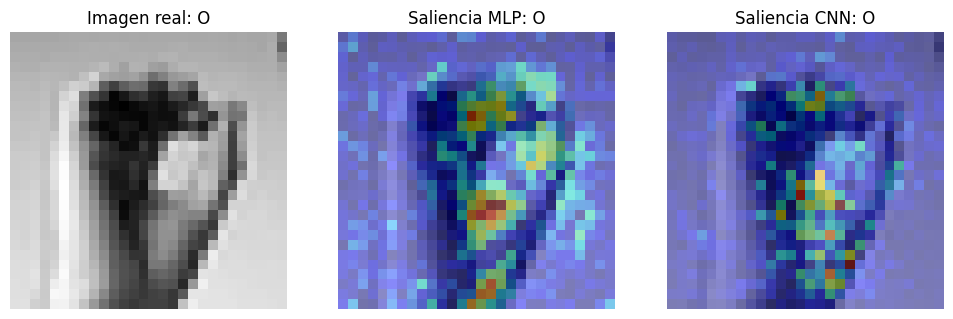

**Lectura:** Se compara la sensibilidad de MLP y CNN ante los mismos píxeles. Grad-CAM corresponde a CNN; la saliencia permite analizar ambas arquitecturas. Deben examinarse manos y fondos sin atribuir causalidad a los mapas.


6. RESUMEN DE RESULTADOS (SIN CONCLUSIONES DEFINITIVAS)


,Modelo,Configuración,F1 val media,F1 val perturbada,F1 test observado,Parámetros,Tiempo (s)
0,MLP,Baseline,0.99905,0.96792,0.93605,109061,12.68947
1,CNN,Filtros 12-24,1.00000,0.99401,0.99929,78389,49.06693


**Selección provisional:** CNN, elegida antes de consultar test mediante F1 de validación, robustez sintética y complejidad. La interpretación técnica extensa y las conclusiones se redactarán al finalizar.


Carpeta de gráficos y tablas: /content/resultados_e3_v3_20261122_232236_471257
El notebook ejecutado conserva también las tablas y figuras visibles para capturas.


In [9]:
def generar_reporte(tabla, estabilidad, seleccion, ganadora, final):
    """Resume las decisiones experimentales sin redactar todavía conclusiones finales."""
    filas = []
    for tipo in ("MLP", "CNN"):
        item = seleccion[tipo]
        est = estabilidad.loc[(estabilidad["Modelo"] == tipo) &
                             (estabilidad["Experimento"] == item["resumen"]["Experimento"])].iloc[0]
        prueba = final.loc[final["Modelo"] == tipo].iloc[0]
        filas.append({"Modelo": tipo, "Configuración": item["resumen"]["Experimento"],
                      "F1 val media": est["F1 media"],
                      "F1 val perturbada": est["Robustez media"],
                      "F1 test observado": prueba["F1 macro"],
                      "Parámetros": item["resumen"]["Parametros"],
                      "Tiempo (s)": item["resumen"]["Tiempo (s)"]})
    resumen = pd.DataFrame(filas)
    display(resumen.round(5))
    guardar_tabla(resumen, "resumen_tecnico_v3")
    nota(f"**Selección provisional:** {ganadora}, elegida antes de consultar test "
         "mediante F1 de validación, robustez sintética y complejidad. "
         "La interpretación técnica extensa y las conclusiones se redactarán al finalizar.")
    print("\nCarpeta de gráficos y tablas:", CARPETA)
    print("El notebook ejecutado conserva también las tablas y figuras visibles para capturas.")
    return resumen


def main():
    """Pipeline 3.4 adaptado: datos -> análisis -> preprocesamiento -> modelos ->
    entrenamiento/regularización -> optimización -> validación/robustez ->
    selección -> test -> auditoría/XAI -> reporte.
    """
    global CARPETA
    CARPETA = os.path.join(BASE_RESULTADOS, "resultados_e3_v3_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    os.makedirs(CARPETA, exist_ok=True)
    print("Evidencias de esta ejecución:", CARPETA)
    print("\n1. CARGA, ANÁLISIS Y PREPROCESAMIENTO")
    bruto_train, bruto_test = cargar_datos()
    train = filtrar_vocales(bruto_train)
    test = filtrar_vocales(bruto_test)
    analizar_dataset(train, test)
    datos = preprocesar(train, test)
    print("Train:", datos["X_train"].shape,
          "| Val:", datos["X_val"].shape,
          "| Test:", datos["X_test"].shape)
    comprobar_duplicados(datos)
    nota("**Lectura:** Solo se usan A, E, I, O y U; se normaliza de 0–255 a 0–1 "
         "y se separa el 20% del train original con estratificación. "
         "El test se reserva para después de seleccionar los modelos.")

    print("\n2. CONSTRUCCIÓN, ENTRENAMIENTO, REGULARIZACIÓN Y OPTIMIZACIÓN")
    registros, experimentos = optimizar_modelo(datos)

    print("\n3. SEGUNDA VALIDACIÓN, ROBUSTEZ Y SELECCIÓN")
    seleccion, ganadora, estabilidad = comprobar_estabilidad((train, test), datos,
                                                             registros, experimentos)

    print("\n3B. DESPLAZAMIENTOS Y DATA AUGMENTATION")
    robustez_adicional = comparar_robustez_aumento(train)

    print("\n4. EVALUACIÓN DE MODELOS SELECCIONADOS EN PRUEBA")
    resultados, tabla_test, modelos = evaluar_modelos_seleccionados(datos, seleccion)

    # Porcentaje de errores de ambos modelos
    y = datos["y_test"]
    pred_mlp = resultados["MLP"]["pred"]
    pred_cnn = resultados["CNN"]["pred"]

    for nombre, pred in (("MLP", pred_mlp), ("CNN", pred_cnn)):
        errores = np.sum(pred != y)
        porcentaje = errores / len(y) * 100
        print(f"{nombre}: {errores} errores de {len(y)} imágenes ({porcentaje:.2f} %)")

    # Comparación sobre las mismas imágenes de prueba
    indices = list(np.where(pred_cnn != y)[0][:1])
    indices += list(np.where((pred_mlp != y) & (pred_cnn == y))[0][:4])
    indices += list(np.where((pred_mlp == y) & (pred_cnn == y))[0][:3])
    indices = list(dict.fromkeys(indices))

    tabla = pd.DataFrame({
        "Imagen test": indices,
        "Real": [CLASES[y[i]] for i in indices],
        "Predicción MLP": [CLASES[pred_mlp[i]] for i in indices],
        "Predicción CNN": [CLASES[pred_cnn[i]] for i in indices]
    })
    display(tabla)
    guardar_tabla(tabla, "comparacion_mismas_imagenes")

    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax in axes.ravel():
        ax.axis("off")

    for ax, i in zip(axes.ravel(), indices):
        ax.imshow(datos["X_test"][i, :, :, 0], cmap="gray")
        ax.set_title(
            f"Real: {CLASES[y[i]]}\n"
            f"MLP: {CLASES[pred_mlp[i]]}\n"
            f"CNN: {CLASES[pred_cnn[i]]}"
        )
        ax.axis("off")

    plt.tight_layout()
    guardar_figura("comparacion_mismas_imagenes")
    plt.show()


    print("\n5. AUDITORÍA DE ERRORES, CLASES Y EXPLICABILIDAD")
    visualizar_errores(datos, resultados, tipo="MLP")
    visualizar_errores(datos, resultados, tipo="CNN")
    auditoria = auditar_modelo(datos, resultados)
    explicar_modelo(datos, resultados, modelos)

    print("\n6. RESUMEN DE RESULTADOS (SIN CONCLUSIONES DEFINITIVAS)")
    resumen = generar_reporte(experimentos, estabilidad, seleccion, ganadora, tabla_test)
    return {
    "experimentos": experimentos,
    "estabilidad": estabilidad,
    "robustez_adicional": robustez_adicional,
    "test": tabla_test,
    "auditoria": auditoria,
    "modelo_recomendado": ganadora,
    "resumen": resumen
}


resultados_v3 = main()

## 9. Justificación de decisiones técnicas

### 9.1. Preprocesamiento y Pipeline Integrado

Se seleccionaron las cinco vocales A, E, I, O y U, normalizando las imágenes de 28×28 píxeles a valores entre 0 y 1. Se utilizó una división estratificada para mantener la proporción de las clases y separar entrenamiento, validación y prueba.

El Pipeline se organizó mediante funciones reutilizables y una función principal `main()`, permitiendo integrar las etapas y ejecutar los experimentos de manera ordenada.

### 9.2. Arquitecturas MLP y CNN

Se implementaron ambas arquitecturas para comparar su capacidad de clasificación bajo condiciones similares. La MLP procesa los píxeles como un vector, mientras que la CNN utiliza capas convolucionales para aprender patrones espaciales de las imágenes.

Los resultados mostraron un mejor desempeño de la CNN, especialmente al reconocer vocales que la MLP confundía con mayor frecuencia.

### 9.3. Técnicas de regularización

Se probaron Dropout, Early Stopping, regularización L2, Batch Normalization y Data Augmentation para evaluar su efecto sobre el aprendizaje y la generalización.

Dropout 0.30 disminuyó la F1 de validación de la MLP, mientras que Early Stopping no detuvo anticipadamente el entrenamiento. L2 y Batch Normalization permitieron evaluar otras configuraciones, pero no demostraron una mejora significativa de F1 en la CNN, que ya alcanzaba valores muy altos.

### 9.4. Optimización de hiperparámetros

Se modificaron individualmente hiperparámetros como Learning Rate, Batch Size, cantidad de neuronas, filtros convolucionales y épocas, comparando sus resultados mediante métricas y curvas de aprendizaje.

La CNN con filtros 12-24 mantuvo una F1 del 100% en validación y redujo sus parámetros de 219.909 a 78.389, una disminución del 64,4% respecto a la CNN inicial. Esto permitió obtener una arquitectura más eficiente sin una pérdida observable de F1 en validación.

### 9.5. Robustez y Data Augmentation

Se evaluó la CNN aplicando pequeñas modificaciones de iluminación, ruido y desplazamientos de un píxel en cuatro direcciones para comprobar su estabilidad.

Data Augmentation aumentó la F1 media ante desplazamientos de 98,31% a 99,16%. Sin embargo, algunos resultados individuales empeoraron y el entrenamiento requirió más tiempo, por lo que no se consideró una mejora uniforme.

### 9.6. Auditoría y explicabilidad

Se utilizaron matrices de confusión, métricas por vocal y herramientas de explicabilidad para identificar errores y analizar el comportamiento de los modelos.

La MLP presentó mayores dificultades con la vocal O, mientras que la CNN cometió solamente un error en prueba. Grad-CAM y los mapas de saliencia permitieron observar regiones relevantes de las imágenes, aunque no permiten descartar completamente posibles sesgos.

Se observaron diferencias en la distribución de las vocales entre entrenamiento y prueba, lo que debe considerarse al interpretar las métricas. Además, algunos mapas Grad-CAM destacaron tanto regiones de las manos como zonas del fondo, por lo que sería conveniente comprobar el comportamiento del modelo con imágenes externas.

### 9.7. Selección del modelo final

Se seleccionó la CNN de filtros 12-24 considerando los resultados de validación, la robustez y la cantidad de parámetros.

Esta configuración obtuvo una F1 de validación del 100% y una Accuracy del 99,94% en prueba, con 78.389 parámetros. Por su rendimiento y menor complejidad, se consideró la alternativa más conveniente entre las configuraciones evaluadas, sin asumir que su desempeño será perfecto en imágenes externas.

## 10. Conclusiones y mejoras futuras

### 10.1. Resultados generales

Los experimentos demostraron que la arquitectura CNN obtuvo mejores resultados que la MLP en la clasificación de las cinco vocales. La CNN seleccionada alcanzó una Accuracy del 99,94% y una F1 macro del 99,93% en prueba, mientras que la MLP obtuvo un 94,41% de Accuracy.

La optimización también permitió comprobar que una red más pequeña puede mantener un rendimiento elevado sin necesitar una mayor cantidad de filtros o neuronas.

### 10.2. Fortalezas del modelo y del Pipeline

La principal fortaleza fue conseguir un alto rendimiento utilizando una CNN de 78.389 parámetros, reduciendo su complejidad un 64,4% respecto a la CNN inicial.

Además, el Pipeline permitió realizar experimentos controlados, comparar configuraciones y evaluar su robustez mediante métricas y gráficos, facilitando la selección del modelo.

### 10.3. Limitaciones y riesgos

El modelo fue evaluado utilizando imágenes del dataset Sign Language MNIST, limitadas a cinco vocales. Por lo tanto, sus buenos resultados no garantizan el mismo desempeño con imágenes externas, diferentes personas o condiciones de captura.

También se observó sensibilidad ante pequeños desplazamientos. Aunque se utilizaron herramientas XAI para interpretar las predicciones, no es posible descartar completamente posibles sesgos o dependencias de características del conjunto de datos.

### 10.4. Posibles mejoras futuras

Como mejora futura, se propone evaluar el modelo con imágenes externas tomadas bajo diferentes condiciones de iluminación, posición y fondo, para comprobar mejor su capacidad de generalización.

También sería conveniente perfeccionar Data Augmentation para aumentar la resistencia a desplazamientos, repetir las pruebas con distintas semillas y ampliar la auditoría con datos más variados.

### 10.5. Conclusión final

La evaluación permitió aplicar técnicas de regularización, optimización y auditoría para mejorar una solución de Deep Learning.

Se concluye que la CNN de filtros 12-24 representa la alternativa más conveniente entre las configuraciones evaluadas, al combinar un rendimiento predictivo elevado con una menor complejidad. Los experimentos también demostraron que aumentar el tamaño del modelo o aplicar más técnicas no garantiza mejores resultados, por lo que las decisiones deben fundamentarse en evidencia experimental.

## 11. Referencias

1. **Material docente.** *Actividad 3.4: Notebook Pipeline Integrado – Estudiante*. Material proporcionado por la docente de Técnicas Avanzadas de Machine Learning.

2. **Material docente.** *Actividad 3.5: Notebook Refinamiento Técnico – Estudiante*. Material proporcionado por la docente de Técnicas Avanzadas de Machine Learning.

3. **datamunge.** *Sign Language MNIST*. Kaggle. Dataset utilizado para clasificar las vocales A, E, I, O y U.  

4. **TensorFlow.** *Convolutional Neural Network (CNN)*. Documentación oficial sobre redes neuronales convolucionales.  

5. **TensorFlow.** *Data augmentation*. Documentación oficial sobre técnicas de aumento de datos para imágenes.  

6. **Scikit-learn.** *Model evaluation: Quantifying the quality of predictions*. Documentación sobre métricas de evaluación de modelos.  

7. **Keras.** *Grad-CAM class activation visualization*. Documentación y ejemplo de Inteligencia Artificial Explicable.  